# Symmetry protection of the boundary local density of states in a lossy Su–Schrieffer–Heeger lattice

This notebook reproduces the study end to end. Running it from top to bottom performs every
calculation, writes every figure used in the manuscript to `figures/`, stores all numerical
results in `results/results.json`, and prints a consolidated summary in the final section.

Reusable routines live in `src/nh_topo/`; the orchestration, the parameter choices and the
reasoning are all here.

---

## What the study establishes

A one-dimensional SSH chain with loss on one sublattice is usually described as "chirally
symmetric with loss added". That description is wrong. Correcting it identifies what protects the
recovery of exact zero modes in a finite lossy chain, and what that recovery does to the boundary
local density of states.

1. **The Hermitian chiral relation fails.** For $H = H_0 - i\gamma P_B$ the relation
   $\sigma_z H \sigma_z = -H$ is violated by exactly $2\gamma$. The relation that holds is
   $\sigma_z H \sigma_z = -H^\dagger$ (equivalently for the shifted operator $\tilde H$), the chiral
   symmetry of the Kawabata-Shiozaki-Ueda-Sato classification, written CS$^\dagger$ here.

2. **The shifted Hamiltonian squares exactly.** Because $H_0$ anticommutes with $\sigma_z$ for any
   real bond configuration, $\tilde H^2 = H_0^2 - (\gamma/2)^2$, so every Hermitian pair $\pm\varepsilon$
   becomes a two-level block with eigenvalues $-i\gamma/2 \pm \sqrt{\varepsilon^2 - \gamma^2/4}$.

3. **Loss suppresses finite-size hybridisation.** That symmetry lets a mode leave the imaginary
   axis only by pairing with a partner at equal decay rate. Loss separates the two boundary modes
   in the imaginary direction and removes the partner, closing the channel.

4. **The boundary doublet has its own exceptional point** at $\gamma = 2\delta_0$, where
   $\delta_0 \sim e^{-N/\xi}$ is the bare Hermitian splitting. This is exponentially smaller than
   the bulk exceptional point.

5. **Crossing it doubles the measurable boundary spectral weight**, from $W_0/2$ to
   $W_0 = 1 - (t_1/t_2)^2$.

6. **A full-wave Maxwell calculation confirms the picture** in a fabricable dielectric structure:
   the boundary enhancement is present in the topological geometry, absent in the trivial control,
   and attenuated by material loss.

## Physical principles

An emitter placed in a structured medium radiates at a rate set by the local density of optical
states (LDOS) at its position and frequency. In a lattice model the LDOS at site $i$ follows from
the retarded Green function,

$$\rho_i(\omega) = -\frac{1}{\pi}\,\mathrm{Im}\,G^R_{ii}(\omega),
\qquad G^R(\omega) = \left[(\omega + i\eta)\mathbb{1} - H\right]^{-1}.$$

A topological boundary mode concentrates spectral weight at the edge of the chain, so an emitter
there sees an enhanced LDOS inside the band gap. The questions this study answers are how that
enhancement behaves when the lattice is lossy, which parts of it are protected against disorder,
and why.

## Mathematical formulation

**Lattice model.** $N$ unit cells, each with sites $A$ and $B$, intra-cell hopping $t_1$,
inter-cell hopping $t_2$, and loss on the $B$ sublattice only:

$$H = \sum_n \left[t_1\,a_n^\dagger b_n + t_2\,a_{n+1}^\dagger b_n + \text{h.c.}\right]
      - i\gamma\sum_n b_n^\dagger b_n .$$

All hoppings are real and reciprocal, so $H = H^{\mathsf T}$ is complex symmetric and passive:
every eigenvalue lies in the strip $\mathrm{Im}\,E \in [-\gamma, 0]$. Reciprocity excludes the
non-Hermitian skin effect, so the conventional bulk–boundary correspondence applies.

The Bloch Hamiltonian is $H(k) = \begin{pmatrix} 0 & q(k) \\ q^*(k) & -i\gamma\end{pmatrix}$ with
$q(k) = t_1 + t_2 e^{-ik}$, giving

$$E_\pm(k) = -\tfrac{i\gamma}{2} \pm \sqrt{|q(k)|^2 - \left(\tfrac{\gamma}{2}\right)^2}.$$

The radicand turns negative when $\gamma/2$ exceeds $\min_k |q(k)| = |t_2 - t_1|$, so the **bulk**
exceptional point sits at $\gamma_{\rm EP} = 2|t_2 - t_1|$. Since $\gamma$ enters only the
diagonal, $q(k)$ is untouched and the winding number is that of the Hermitian chain.

**Symmetry.** Writing $P_B = (\mathbb{1} - \sigma_z)/2$ gives
$H = H_0 - i\frac{\gamma}{2}\mathbb{1} + i\frac{\gamma}{2}\sigma_z$, so the shifted operator

$$\tilde H \equiv H + \tfrac{i\gamma}{2}\mathbb{1} = H_0 + \tfrac{i\gamma}{2}\sigma_z$$

satisfies $\sigma_z \tilde H \sigma_z = -\tilde H^\dagger$. The shift translates every eigenvalue
by $+i\gamma/2$ and leaves the eigenvectors alone, so no spatial observable is affected. (The
relation holds for the unshifted $H$ too; what the shift exposes is the balanced gain-loss form
$\tilde H = H_0 + \tfrac{i\gamma}{2}\sigma_z$, for which $\tilde H^2 = H_0^2 - (\gamma/2)^2\mathbb{1}$
exactly whenever $H_0$ anticommutes with $\sigma_z$.)

Unlike Hermitian chiral symmetry, which forces eigenvalues into $\pm$ pairs, this relation forces
the spectrum to be symmetric about the *imaginary* axis, $E \to -E^*$. A single eigenvalue is
self-conjugate under that map precisely when $\mathrm{Re}\,E = 0$. The symmetry therefore pins the
real energy of an unpaired mode and says nothing about its decay rate, and a mode can leave the
axis only in company with a partner at equal $\mathrm{Im}\,E$.

**Positivity of the LDOS.** With $H = H_0 - i\Gamma$ and $\Gamma = \gamma P_B \succeq 0$, the
resolvent denominator $M = (\omega + i\eta)\mathbb{1} - H = A + iB$ has $A$ real symmetric and
$B = \eta\mathbb{1} + \Gamma$ positive definite for $\eta > 0$. From
$G - G^\dagger = -2i M^{-1} B (M^{-1})^\dagger$,

$$\rho_i(\omega) = \frac{1}{\pi}\sum_j \left(\eta + \gamma [P_B]_{jj}\right)|G_{ij}|^2 \ \ge\ 0 ,$$

so the diagonal resolvent is a genuine spectral function for this passive model.

**Intrinsic versus broadening-dependent quantities.** The integrated edge-to-bulk ratio
$\mathcal{E}$ depends on $\eta$ and is not a figure of merit on its own. The intrinsic quantity is
the boundary spectral weight $W_0 = 1 - (t_1/t_2)^2$, which follows from the analytic zero mode
$\psi_A(n) \propto (-t_1/t_2)^n$ and carries amplitude localisation length
$\xi = 1/\ln(t_2/t_1)$.

## Computational methodology

| Stage | Method | Why |
|---|---|---|
| Spectra and eigenvectors | dense LAPACK on matrices of size $2N \le 120$ | no iterative tolerances, no spectral pollution |
| LDOS | sparse linear solve for $G^R$ | direct, avoids forming the full inverse |
| LDOS cross-check | biorthogonal eigendecomposition | independent route to the same operator |
| LDOS second cross-check | semi-infinite surface Green function by iterative decimation | different algorithm *and* different geometry |
| Boundary-mode tracking | overlap with the clean mode (adiabatic continuation) | uses no energy information, so measuring its energy is not circular |
| Disorder statistics | 200 seeded realisations per point, standard errors reported | quantifies ensemble uncertainty |
| Full-wave validation | finite-difference frequency domain with a stretched-coordinate absorber | solves Maxwell's equations directly |

**A note on mode identification.** An earlier version of this project identified the boundary mode
by a fixed boundary-weight threshold. That fails in two opposite ways. At strong disorder a
genuinely protected mode whose localisation has been stretched can drop below the threshold while
band-edge bulk states rise above it, and the diagnostic then reports the $|\mathrm{Re}\,E|\approx
1.2\,\bar t$ of a bulk state as a displacement of the zero mode. Separately, a *hybridised* doublet
shares its weight between the two ends of the chain, so each end carries only about half of $W_0$
and a fixed threshold misses it entirely. Both failures are avoided here: the detector is
size-aware and restricted to in-gap states, and the disorder diagnostic tracks the mode by overlap.
Both behaviours are covered by regression tests in `tests/`.

In [1]:
import json
import os
import sys
import time

import numpy as np

sys.path.insert(0, "src")

import nh_topo as nt
from nh_topo import figures as F
from nh_topo import electromagnetics as em

FIGDIR, RESDIR = "figures", "results"
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)
F.apply_style()

# --- Physical parameters -------------------------------------------------
# Energies (hoppings, loss rate, disorder width, broadening) are measured in
# units of the mean hopping tbar = (t1 + t2)/2, which this operating point sets
# to one, so every number below is quoted in units of tbar. The ratio
# t2/t1 = 1.5 places the chain in the topological phase; gamma = 0.3 sits well
# below the bulk exceptional point at 2|t2 - t1| = 0.8, so the bulk bands are
# unbroken.
T1, T2, GAMMA, N_CELLS = 0.8, 1.2, 0.3, 20
TBAR = 0.5 * (T1 + T2)
assert abs(TBAR - 1.0) < 1e-12, "the operating point defines the energy unit"

# Spectral broadening of the emitter and half-width of the gap window used for
# all integrated quantities.
ETA, GAP_HW = 0.05, 0.15

# Trivial-phase control: t2/t1 = 0.6 with the same t1 and loss (opposite dimerisation).
TRIVIAL_RATIO = 0.6

# Disorder ensembles. The range extends past the point where protection fails so
# that the breakdown is inside the figures rather than beyond them.
W_VALS = [0.0, 0.1, 0.2, 0.4, 0.6, 1.0, 1.5]
N_REALIZATIONS, SEED = 200, 12345

EDGE_SITE = 0
BULK_SITE = nt.central_bulk_site(N_CELLS)   # central A site: parity-safe
# 61 points integrates the gap window to better than 1e-4 relative; the
# convergence of this choice is demonstrated in Section 7.
GAP_GRID = np.linspace(-GAP_HW, GAP_HW, 61)

results = {"parameters": dict(energy_unit="mean hopping (t1 + t2)/2 = 1",
                              t1=T1, t2=T2, gamma=GAMMA, N=N_CELLS, eta=ETA,
                              gap_half_width=GAP_HW, W_vals=W_VALS,
                              n_realizations=N_REALIZATIONS, seed=SEED)}

print(f"t1 = {T1}, t2 = {T2}, t2/t1 = {T2/T1:.2f}, gamma = {GAMMA}, N = {N_CELLS}")
print(f"bulk exceptional point   2|t2 - t1| = {nt.exceptional_point_threshold(T1, T2):.3f}")
print(f"analytic edge weight     1 - (t1/t2)^2 = {nt.analytic_edge_weight(T1, T2):.6f}")
print(f"analytic localisation    1/ln(t2/t1)   = {nt.localization_length(T1, T2):.6f}")

t1 = 0.8, t2 = 1.2, t2/t1 = 1.50, gamma = 0.3, N = 20
bulk exceptional point   2|t2 - t1| = 0.800
analytic edge weight     1 - (t1/t2)^2 = 0.555556
analytic localisation    1/ln(t2/t1)   = 2.466303


---
# 1. The Hamiltonian and its symmetry

The first task is to establish what the model actually is. We build the Hamiltonian, confirm it is
complex symmetric and passive, and then test the two candidate symmetry relations against it.

In [2]:
H = nt.build_ssh(N_CELLS, T1, T2, GAMMA)

props = nt.verify_properties(H)
results["hamiltonian"] = props
print("complex symmetric (H = H^T) :", props["is_symmetric"])
print("Hermitian                   :", props["is_hermitian"])
print("passive (Im E <= 0)         :", props["all_passive"])

evals_all = np.linalg.eigvals(H)
print(f"Im E range                  : [{evals_all.imag.min():.6f}, {evals_all.imag.max():.2e}]")

complex symmetric (H = H^T) : True
Hermitian                   : False
passive (Im E <= 0)         : True
Im E range                  : [-0.300000, -1.34e-07]


### The two candidate symmetries

$\sigma_z H \sigma_z = -H$ should fail by exactly $2\gamma$, while
$\sigma_z \tilde H \sigma_z = -\tilde H^\dagger$ should hold to machine precision.

The next cell checks a stronger, exact statement. Because $H_0$ anticommutes with $\sigma_z$ for any
real bond configuration, $\tilde H^2 = H_0^2 - (\gamma/2)^2\mathbb{1}$, so every eigenvalue of $H$
follows the square-root law $E = -i\gamma/2 \pm \sqrt{\varepsilon^2 - \gamma^2/4}$ with
$\varepsilon \ge 0$ an eigenvalue of $H_0$. Each Hermitian $\pm\varepsilon$ pair becomes a two-level
system with its own exceptional point at $\gamma = 2\varepsilon$.

In [3]:
report = nt.symmetry_report(H, GAMMA)
results["symmetry"] = report

print(f"|| sz H sz + H ||_max          = {report['chiral_residual']:.6f}"
      f"   (2*gamma = {2*GAMMA:.6f})")
print(f"|| sz H~ sz + H~^dagger ||_max = {report['cs_dagger_residual']:.3e}")
print(f"max distance of -E* to spec    = {report['spectral_symmetry']:.3e}")
print(f"eigenvalues pinned at Re E = 0 = {report['n_pinned']}")
print()
print("Hermitian chiral symmetry holds :", report["hermitian_chiral_holds"])
print("CS-dagger symmetry holds        :", report["cs_dagger_holds"])

# The shift must not disturb any eigenvector, or it would change the LDOS.
Ht = nt.shifted_hamiltonian(H, GAMMA)
ev, vecs = np.linalg.eig(H)
rigid = max(np.abs(Ht @ vecs[:, n] - (ev[n] + 1j*GAMMA/2) * vecs[:, n]).max()
            for n in range(ev.size))
results["shift_is_rigid_residual"] = float(rigid)
print(f"\nlargest deviation from H~ v = (E + i*gamma/2) v : {rigid:.3e}")

|| sz H sz + H ||_max          = 0.600000   (2*gamma = 0.600000)
|| sz H~ sz + H~^dagger ||_max = 0.000e+00
max distance of -E* to spec    = 6.884e-15
eigenvalues pinned at Re E = 0 = 2

Hermitian chiral symmetry holds : False
CS-dagger symmetry holds        : True

largest deviation from H~ v = (E + i*gamma/2) v : 3.511e-15


In [4]:
# Exact reduction. H0 anticommutes with sigma_z for any real bond configuration,
# so Htilde^2 = H0^2 - (gamma/2)^2 exactly and every eigenvalue of H follows the
# square-root law E = -i*gamma/2 +/- sqrt(eps^2 - gamma^2/4), eps >= 0 in spec(H0).
# The bulk and edge exceptional points are two instances of this formula, and the
# two-level description of the boundary doublet is exact. On-site disorder breaks it.
sz = nt.sublattice_operator(N_CELLS)
rng_x = np.random.default_rng(SEED + 1)
exact = {"clean": {"square_identity": nt.square_identity_residual(H, GAMMA),
                   "square_root_law": nt.square_root_law_residual(H, GAMMA)},
         "cs_dagger_unshifted": float(np.abs(sz @ H @ sz + H.conj().T).max())}
for W in (0.6, 1.5):
    sq_b, law_b, sq_o = [], [], []
    for _ in range(50):
        Hb = nt.make_disordered_ssh(N_CELLS, T1, T2, GAMMA, W, "bond", rng_x)
        Ho = nt.make_disordered_ssh(N_CELLS, T1, T2, GAMMA, W, "on_site", rng_x)
        sq_b.append(nt.square_identity_residual(Hb, GAMMA))
        law_b.append(nt.square_root_law_residual(Hb, GAMMA))
        sq_o.append(nt.square_identity_residual(Ho, GAMMA))
    exact[f"W={W:g}"] = {"bond_square_identity_max": float(max(sq_b)),
                         "bond_square_root_law_max": float(max(law_b)),
                         "onsite_square_identity_mean": float(np.mean(sq_o))}
results["exact_reduction"] = exact

print(f"CS-dagger residual of the unshifted H     : {exact['cs_dagger_unshifted']:.1e}")
print(f"clean chain: ||Ht^2 - H0^2 + (g/2)^2||    : {exact['clean']['square_identity']:.1e}")
print(f"clean chain: spectrum vs square-root law  : {exact['clean']['square_root_law']:.1e}")
for W in (0.6, 1.5):
    d = exact[f"W={W:g}"]
    print(f"W = {W:3.1f}  bond: identity {d['bond_square_identity_max']:.1e}, "
          f"law {d['bond_square_root_law_max']:.1e}   |   on-site: identity "
          f"{d['onsite_square_identity_mean']:.3f}")

CS-dagger residual of the unshifted H     : 0.0e+00
clean chain: ||Ht^2 - H0^2 + (g/2)^2||    : 0.0e+00
clean chain: spectrum vs square-root law  : 3.1e-15
W = 0.6  bond: identity 0.0e+00, law 2.2e-14   |   on-site: identity 0.088
W = 1.5  bond: identity 0.0e+00, law 3.0e-14   |   on-site: identity 0.220


### Which perturbations respect the symmetry

Bond disorder is real and purely off-diagonal, so it leaves $\tilde H$ in the form required by the
symmetry at any strength. On-site disorder adds a real diagonal term $V$, which breaks the relation
by $2V$. This is what makes the two disorder classes used later genuinely distinct rather than two
arbitrary choices.

    W    bond residual   on-site residual
  0.0        0.000e+00             0.0000
  0.2        0.000e+00             0.1994
  0.6        0.000e+00             0.5774
  1.0        0.000e+00             0.9575
  1.5        0.000e+00             1.4987


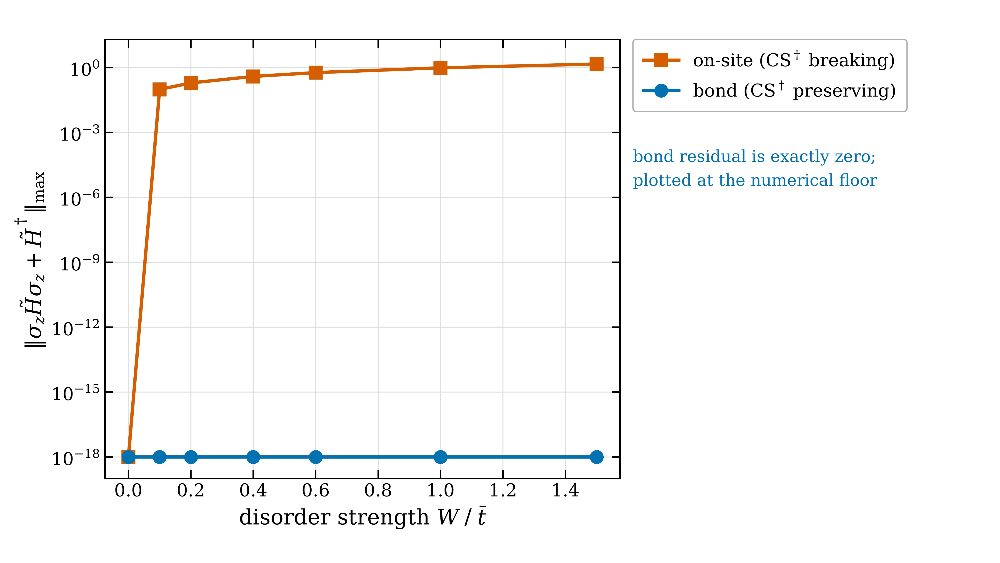

In [5]:
W_probe = [0.0, 0.2, 0.6, 1.0, 1.5]
rng = np.random.default_rng(SEED)
rows = []
for W in W_probe:
    Hb = nt.make_disordered_ssh(N_CELLS, T1, T2, GAMMA, W, "bond", rng)
    Ho = nt.make_disordered_ssh(N_CELLS, T1, T2, GAMMA, W, "on_site", rng)
    rows.append((W, nt.cs_dagger_residual(Hb, GAMMA), nt.cs_dagger_residual(Ho, GAMMA)))

print(f"{'W':>5} {'bond residual':>16} {'on-site residual':>18}")
for W, b, o in rows:
    print(f"{W:5.1f} {b:16.3e} {o:18.4f}")

sym = nt.symmetry_residual_study(N_CELLS, T1, T2, GAMMA, W_VALS, 50, SEED)
results["symmetry_residuals"] = {"W_vals": W_VALS,
                                 "bond": sym["bond"].tolist(),
                                 "bond_max": sym["bond_max"].tolist(),
                                 "on_site": sym["on_site"].tolist()}

fig = F.fig_symmetry_residual(W_VALS, sym["bond"], sym["on_site"])
F.save(fig, FIGDIR, "fig01_symmetry_residual")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig01_symmetry_residual.png", width=760))

---
# 2. Spectrum, boundary modes and the LDOS

With the symmetry established we can read the spectrum in its light. The prediction is that both
boundary modes sit at $\mathrm{Re}\,E = 0$, pinned by the symmetry, while loss separates them
along the imaginary axis, one on the lossless $A$ sublattice and one on the lossy $B$ sublattice.

protected mode : Re E = +4.281e-16   Im E = -0.0000001
lossy mode     : Re E = +3.662e-16   Im E = -0.2999999
winding number : -1.000000


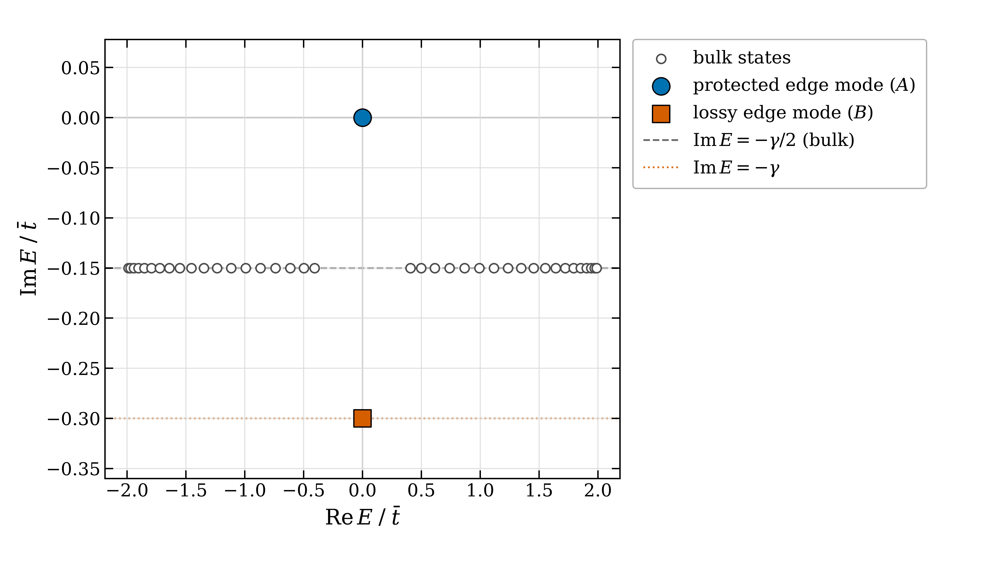

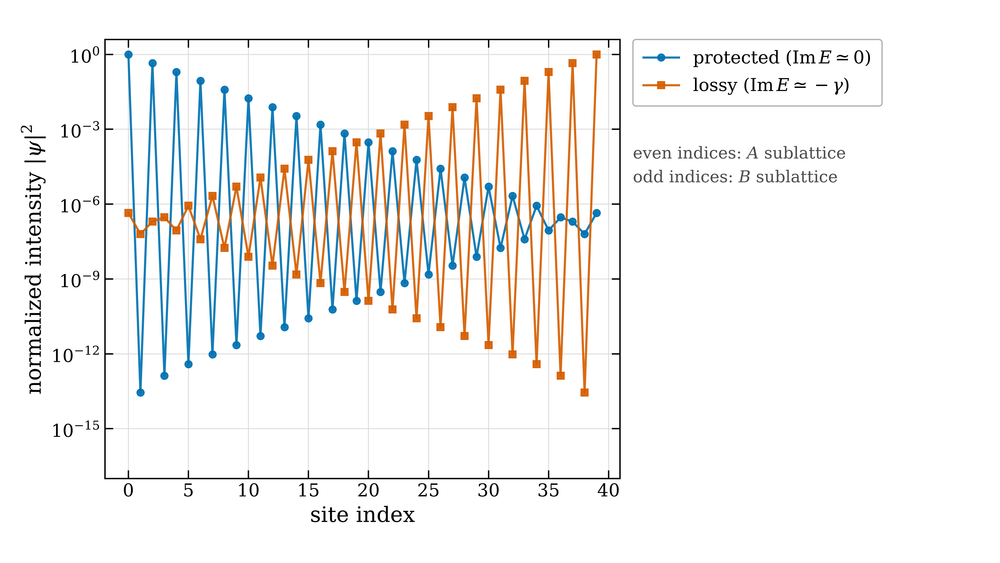

In [6]:
evals, evecs = nt.diagonalize(H)
info = nt.find_edge_modes(evals, evecs, gap_half_width=abs(T2 - T1))

protected = info["protected_idx"][np.argmin(np.abs(evals[info["protected_idx"]].imag))]
lossy = info["lossy_idx"][0]

results["edge_modes"] = {
    "protected_E": [float(evals[protected].real), float(evals[protected].imag)],
    "lossy_E": [float(evals[lossy].real), float(evals[lossy].imag)],
    "winding_number": float(nt.winding_number(T1, T2)),
}
print(f"protected mode : Re E = {evals[protected].real:+.3e}   Im E = {evals[protected].imag:+.7f}")
print(f"lossy mode     : Re E = {evals[lossy].real:+.3e}   Im E = {evals[lossy].imag:+.7f}")
print(f"winding number : {nt.winding_number(T1, T2):.6f}")

F.save(F.fig_complex_spectrum(evals, info["protected_idx"], info["lossy_idx"], GAMMA),
       FIGDIR, "fig02_complex_spectrum")
F.save(F.fig_edge_profile(evecs[:, protected], evecs[:, lossy], N_CELLS),
       FIGDIR, "fig03_edge_profile")
for name in ("fig02_complex_spectrum", "fig03_edge_profile"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

### Localisation length and its finite-size bias

The protected mode decays as $|\psi_A(n)|^2 \propto e^{-2n/\xi}$. Fitting a short chain
underestimates $\xi$ because the exponential tail is truncated by the far boundary before it is
fully developed, so the fit should approach the analytic value from below as $N$ grows. Reporting
the trend rather than a single number is what shows the residual deviation is finite size and not a
defect of the fit.

   N   xi fitted   deviation
   8      2.1285      13.70%
  10      2.2216       9.92%
  12      2.2827       7.44%
  15      2.3401       5.12%
  20      2.3905       3.07%
  30      2.4661       0.01%
  40      2.4663       0.00%
  60      2.4663       0.00%
analytic xi = 2.4663


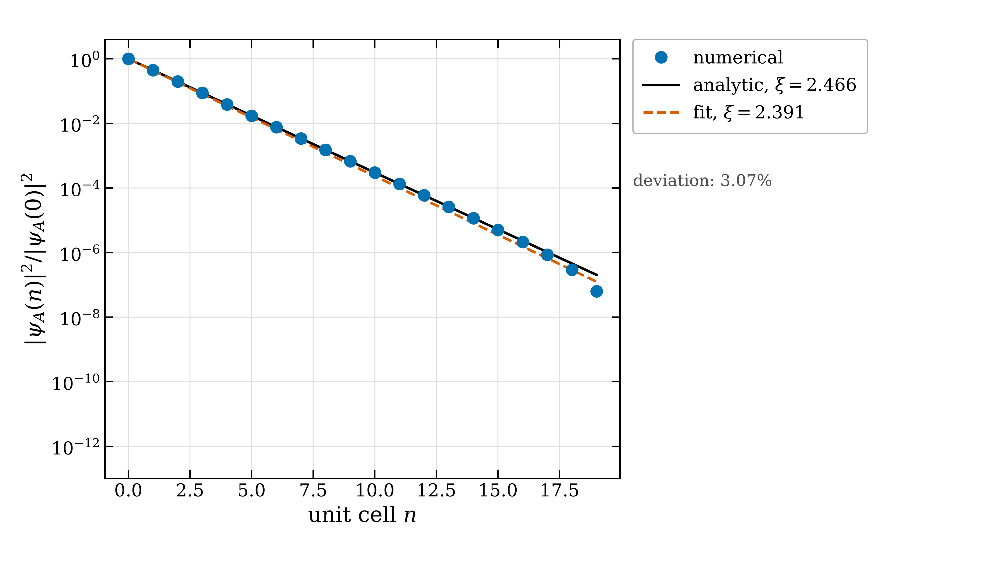

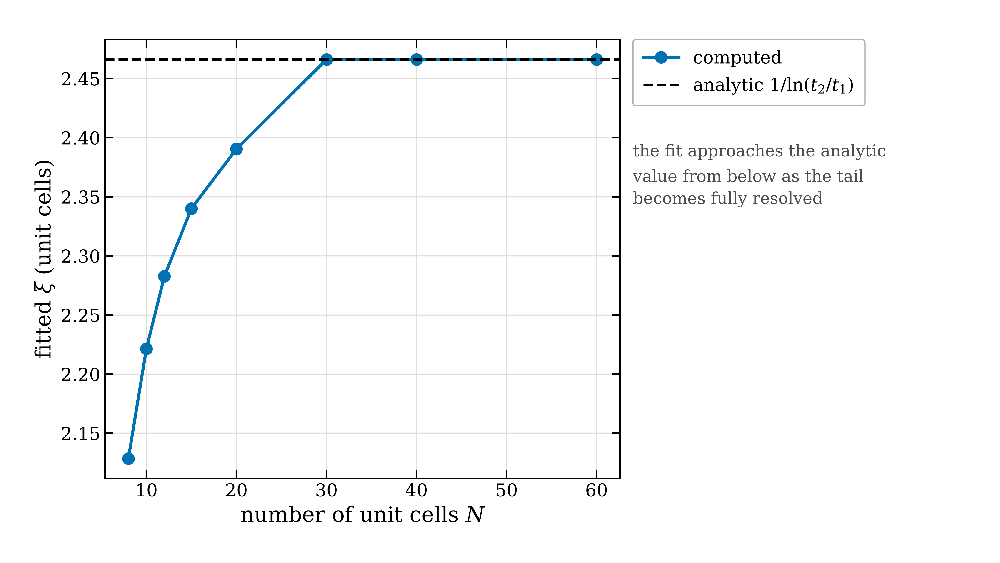

In [7]:
xi_conv = nt.localization_length_convergence(T1, T2, GAMMA, [8, 10, 12, 15, 20, 30, 40, 60])
results["localization_convergence"] = xi_conv

print(f"{'N':>4} {'xi fitted':>11} {'deviation':>11}")
for n, x, e in zip(xi_conv["N_vals"], xi_conv["xi_fit"], xi_conv["rel_error"]):
    print(f"{n:4d} {x:11.4f} {100*e:10.2f}%")
print(f"analytic xi = {xi_conv['xi_analytic']:.4f}")

intensity = np.abs(evecs[:, protected][0::2]) ** 2
intensity = intensity / intensity[0]
xi_fit_N = nt.fit_localization_length(evals, evecs, N_CELLS)
F.save(F.fig_localization_fit(intensity, xi_fit_N, nt.localization_length(T1, T2)),
       FIGDIR, "fig04_localization_fit")
F.save(F.fig_convergence(xi_conv["N_vals"], xi_conv["xi_fit"],
                         "number of unit cells $N$",
                         r"fitted $\xi$ (unit cells)",
                         note="the fit approaches the analytic\nvalue from below as the tail\nbecomes fully resolved",
                         logx=False, reference=xi_conv["xi_analytic"],
                         ref_label=r"analytic $1/\ln(t_2/t_1)$"),
       FIGDIR, "fig05_localization_convergence")
for name in ("fig04_localization_fit", "fig05_localization_convergence"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

### The boundary LDOS

The topological phase concentrates spectral weight at the boundary inside the gap. Two quantities
are computed: the integrated edge-to-bulk ratio $\mathcal{E}$, which depends on the broadening
$\eta$, and the boundary spectral weight $W_0$, which does not.

peak_edge            3.596359
bulk_at_zero         0.132584
enhancement          11.246698
positivity_minimum   0.010820
W0_numeric           0.555557
W0_analytic          0.555556


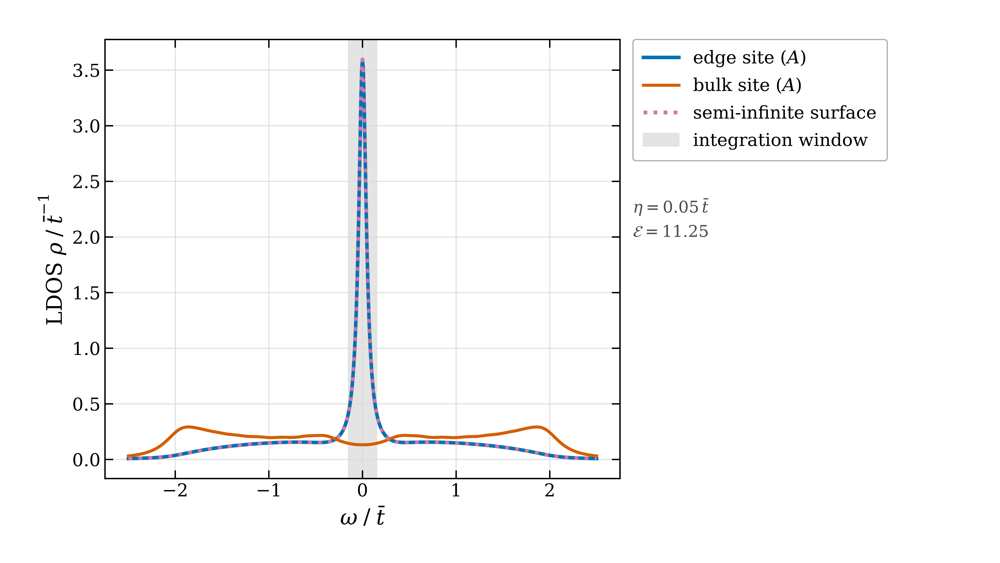

In [8]:
omegas = np.linspace(-2.5, 2.5, 601)
rho_edge = nt.ldos_spectrum(H, EDGE_SITE, omegas, ETA)
rho_bulk = nt.ldos_spectrum(H, BULK_SITE, omegas, ETA)
rho_surf = nt.surface_ldos_spectrum(omegas, T1, T2, GAMMA, ETA, sublattice=0)
enh = nt.enhancement_factor(H, EDGE_SITE, BULK_SITE, GAP_GRID, ETA)

results["ldos"] = {
    "peak_edge": float(rho_edge.max()),
    "bulk_at_zero": float(rho_bulk[np.argmin(np.abs(omegas))]),
    "enhancement": float(enh),
    "positivity_minimum": float(nt.ldos_nonnegativity_min(H, np.linspace(-2, 2, 201), ETA)),
    "W0_numeric": float(nt.edge_mode_spectral_weight(H, EDGE_SITE)),
    "W0_analytic": float(nt.analytic_edge_weight(T1, T2)),
}
for k, v in results["ldos"].items():
    print(f"{k:20s} {v:.6f}")

F.save(F.fig_ldos_spectra(omegas, rho_edge, rho_bulk, rho_surf, GAP_HW, ETA, enh),
       FIGDIR, "fig06_ldos_spectra")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig06_ldos_spectra.png", width=760))

The ratio is not intrinsic: it falls as the broadening grows.
  eta = 0.0100 tbar  ->  E =  14.41
  eta = 0.0226 tbar  ->  E =  13.31
  eta = 0.0512 tbar  ->  E =  11.17
  eta = 0.1158 tbar  ->  E =   7.75


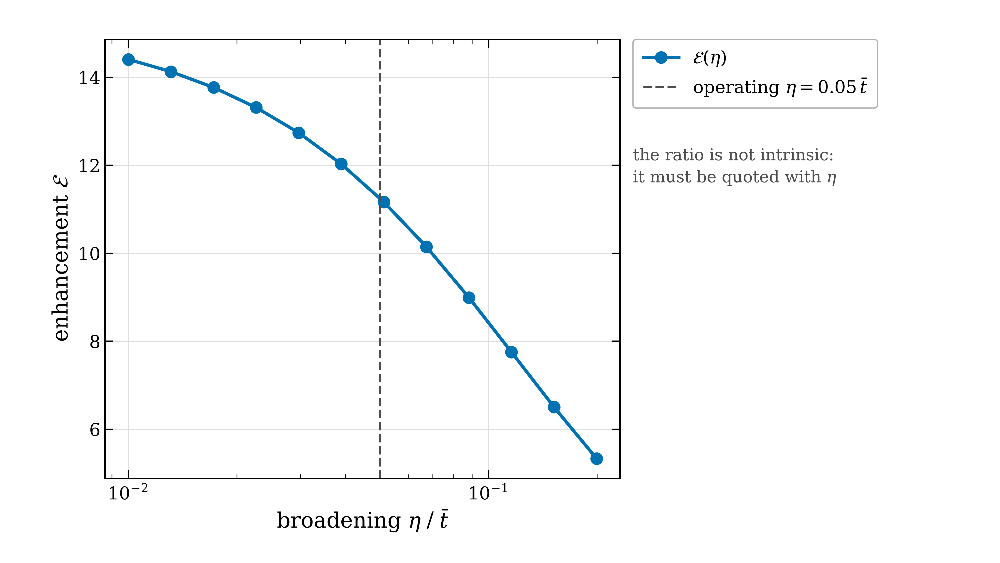

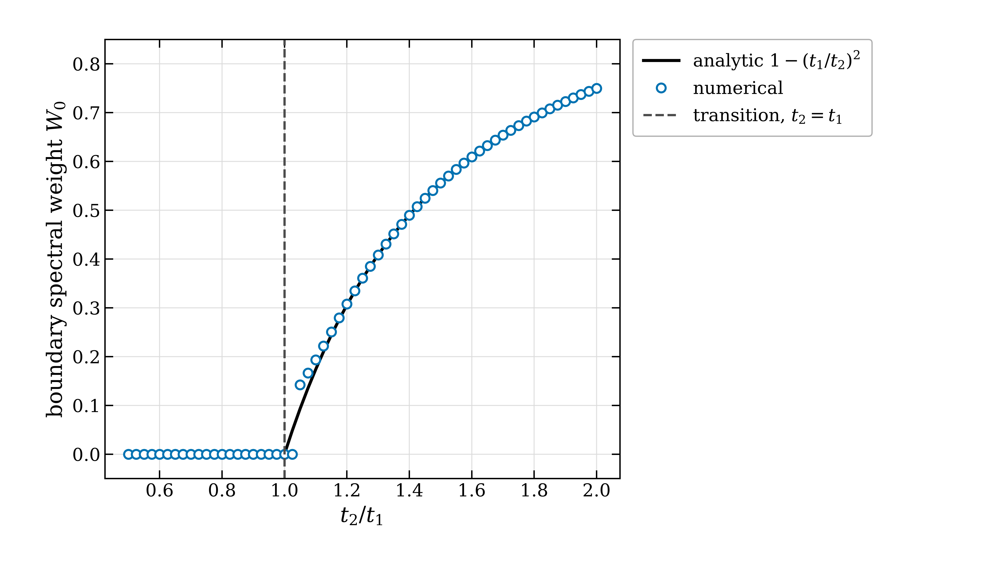

In [9]:
etas = np.logspace(-2, -0.7, 12)
scan = nt.enhancement_vs_eta(H, EDGE_SITE, BULK_SITE, GAP_HW, etas)
results["eta_scaling"] = {"etas": etas.tolist(),
                          "enhancement": scan["enhancement"].tolist()}
print("The ratio is not intrinsic: it falls as the broadening grows.")
for e, v in zip(etas[::3], scan["enhancement"][::3]):
    print(f"  eta = {e:.4f} tbar  ->  E = {v:6.2f}")

r_scan = np.linspace(0.5, 2.0, 61)
w0_num = np.array([nt.edge_mode_spectral_weight(nt.build_ssh(N_CELLS, T1, r*T1, GAMMA), 0)
                   for r in r_scan])
w0_ana = np.array([nt.analytic_edge_weight(T1, r*T1) for r in r_scan])

F.save(F.fig_eta_scaling(etas, scan["enhancement"], ETA), FIGDIR, "fig07_eta_scaling")
F.save(F.fig_edge_weight(r_scan, w0_num, w0_ana), FIGDIR, "fig08_edge_weight")
for name in ("fig07_eta_scaling", "fig08_edge_weight"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

In [10]:
# Close to the transition xi = 1/ln(t2/t1) becomes comparable to the chain length
# and the finite chain departs from the semi-infinite weight 1 - (t1/t2)^2 (the
# first few points above t2/t1 = 1 in the figure). The departure is a finite-size
# effect: it disappears as N grows.
near_r = [1.025, 1.05, 1.1, 1.2]
near = {str(n): {f"{r:.3f}": float(nt.edge_mode_spectral_weight(
                     nt.build_ssh(n, T1, r * T1, GAMMA), 0)) for r in near_r}
        for n in (20, 40, 80)}
results["weight_near_transition"] = {
    "ratios": near_r, "by_N": near,
    "analytic": {f"{r:.3f}": float(nt.analytic_edge_weight(T1, r * T1)) for r in near_r},
    "xi": {f"{r:.3f}": float(nt.localization_length(T1, r * T1)) for r in near_r},
}
print(f"{'t2/t1':>6} {'xi':>7} {'N = 20':>9} {'N = 40':>9} {'N = 80':>9} {'analytic':>9}")
for r in near_r:
    k = f"{r:.3f}"
    print(f"{r:6.3f} {results['weight_near_transition']['xi'][k]:7.2f} "
          + " ".join(f"{near[str(n)][k]:9.4f}" for n in (20, 40, 80))
          + f" {results['weight_near_transition']['analytic'][k]:9.4f}")

 t2/t1      xi    N = 20    N = 40    N = 80  analytic
 1.025   40.50    0.0000    0.0000    0.0000    0.0482
 1.050   20.50    0.1420    0.1028    0.0934    0.0930
 1.100   10.49    0.1934    0.1745    0.1736    0.1736
 1.200    5.48    0.3077    0.3056    0.3056    0.3056


---
# 3. Loss suppresses finite-size hybridisation

In a finite *Hermitian* chain the two boundary modes are degenerate at $E = 0$. Any residual
overlap between them lifts that degeneracy, splitting them to $\pm\delta_0$ with
$\delta_0 \sim e^{-N/\xi}$: small, but never zero. This is the standard limit on how well a
topological mode can be pinned in a chain of finite length.

Under sublattice loss the two modes keep $\mathrm{Re}\,E = 0$ but acquire *different* decay rates.
The symmetry of Section 1 allows a mode to leave the imaginary axis only by pairing with a partner
at equal $\mathrm{Im}\,E$, and loss has removed the partner. The splitting channel is closed.

The comparison below uses identical disorder realisations in both columns, so the only difference
is the presence of loss.

    W      gamma = 0    gamma = 0.3        ratio
  0.0      2.005e-04      3.662e-16     5.48e+11
  0.2      2.016e-04      3.328e-16     6.06e+11
  0.4      2.121e-04      3.580e-16     5.93e+11
  0.6      2.314e-04      2.968e-16     7.80e+11
  1.0      2.840e-04      2.227e-16     1.28e+12


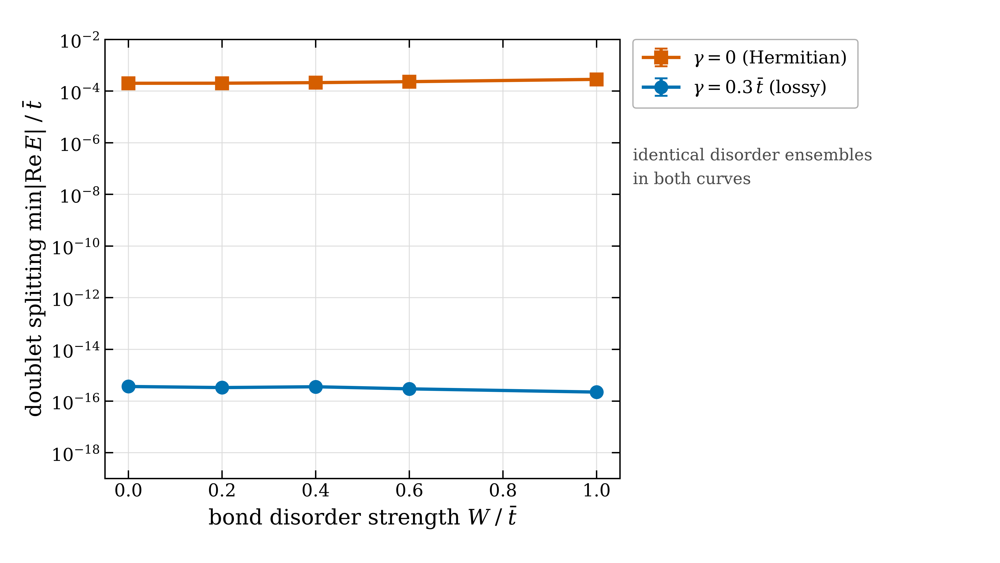

In [11]:
hyb_W = [0.0, 0.2, 0.4, 0.6, 1.0]
hyb = nt.hybridization_study(N_CELLS, T1, T2, [0.0, GAMMA], hyb_W, N_REALIZATIONS, SEED)
results["hybridisation_vs_disorder"] = {
    "W_vals": hyb_W, "gamma_vals": [0.0, GAMMA],
    "splitting": hyb["splitting"].tolist(), "sem": hyb["sem"].tolist()}

print(f"{'W':>5} {'gamma = 0':>14} {'gamma = 0.3':>14} {'ratio':>12}")
for j, W in enumerate(hyb_W):
    a, b = hyb["splitting"][0, j], hyb["splitting"][1, j]
    print(f"{W:5.1f} {a:14.3e} {b:14.3e} {a/max(b, 1e-300):12.2e}")

F.save(F.fig_hybridisation_vs_disorder(hyb_W, hyb["splitting"], hyb["sem"], [0.0, GAMMA]),
       FIGDIR, "fig09_hybridisation_vs_disorder")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig09_hybridisation_vs_disorder.png", width=760))

   N      gamma = 0    gamma = 0.3
   5      9.102e-02      1.358e-03
   8      2.647e-02      2.062e-16
  10      1.180e-02      2.083e-16
  15      1.502e-03      2.887e-16
  20      2.121e-04      3.580e-16
  30      4.145e-06      4.397e-16

delta0 ~ exp(-N/xi):  fitted xi = 2.4614, analytic = 2.4663  (0.20%)


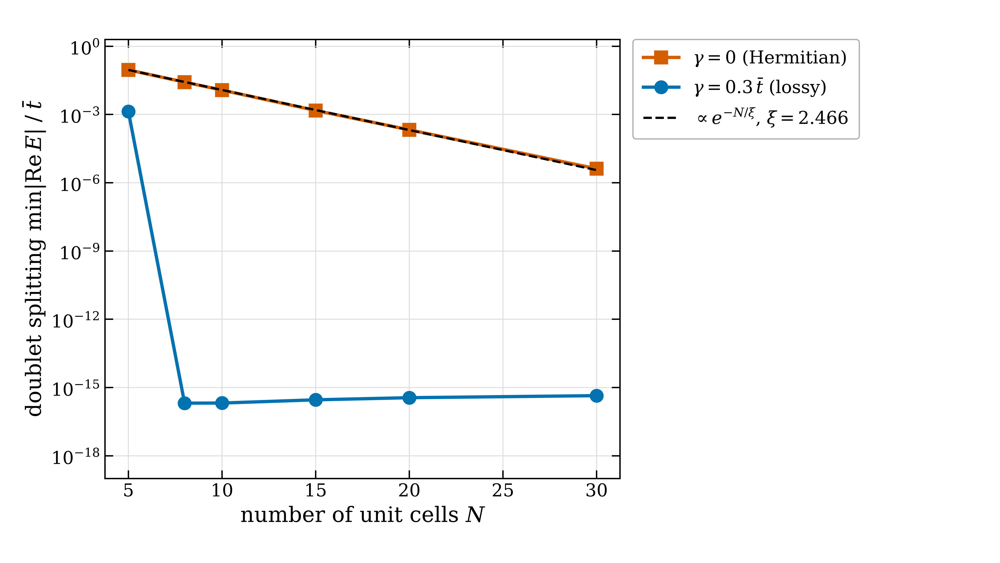

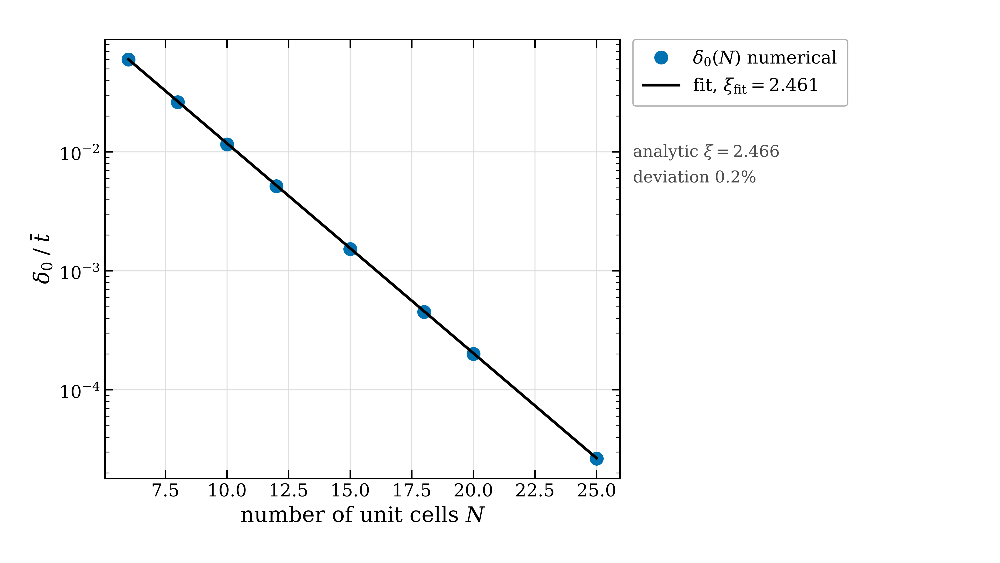

In [12]:
N_scan = [5, 8, 10, 15, 20, 30]
hyb_N = nt.hybridization_vs_size(N_scan, T1, T2, [0.0, GAMMA], 0.4, N_REALIZATIONS, SEED)
results["hybridisation_vs_size"] = {"N_vals": N_scan, "gamma_vals": [0.0, GAMMA],
                                    "splitting": hyb_N["splitting"].tolist()}

print(f"{'N':>4} {'gamma = 0':>14} {'gamma = 0.3':>14}")
for j, n in enumerate(N_scan):
    print(f"{n:4d} {hyb_N['splitting'][0, j]:14.3e} {hyb_N['splitting'][1, j]:14.3e}")

# The Hermitian splitting should itself be exponential in N with decay length xi.
d0 = nt.delta0_size_scaling([6, 8, 10, 12, 15, 18, 20, 25], T1, T2)
results["delta0_scaling"] = {"N_vals": d0["N_vals"].tolist(),
                             "delta0": d0["delta0"].tolist(),
                             "xi_fit": d0["xi_fit"], "xi_analytic": d0["xi_analytic"],
                             "rel_error": d0["rel_error"]}
print(f"\ndelta0 ~ exp(-N/xi):  fitted xi = {d0['xi_fit']:.4f}, "
      f"analytic = {d0['xi_analytic']:.4f}  ({100*d0['rel_error']:.2f}%)")

F.save(F.fig_hybridisation_vs_size(N_scan, hyb_N["splitting"], [0.0, GAMMA],
                                   xi=nt.localization_length(T1, T2)),
       FIGDIR, "fig10_hybridisation_vs_size")
F.save(F.fig_delta0_scaling(d0["N_vals"], d0["delta0"], d0["xi_fit"], d0["xi_analytic"]),
       FIGDIR, "fig11_delta0_scaling")
for name in ("fig10_hybridisation_vs_size", "fig11_delta0_scaling"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

---
# 4. The boundary doublet has its own exceptional point

The mechanism can be stated exactly. The Hermitian doublet $\psi_\pm$ ($H_0\psi_\pm = \pm\delta_0\psi_\pm$)
is mapped onto itself by $\sigma_z$, so its span is invariant under $\tilde H$ and the reduction below
is exact rather than perturbative; it is the edge instance of the square-root law of Section 1.
In the basis of the $A$- and $B$-localised combinations the shifted Hamiltonian restricted to the
doublet is

$$H_{\rm eff} = \begin{pmatrix} +i\gamma/2 & \delta_0 \\ \delta_0 & -i\gamma/2 \end{pmatrix},
\qquad E = \pm\sqrt{\delta_0^2 - \gamma^2/4}.$$

For $\gamma < 2\delta_0$ the radicand is positive and the doublet splits in $\mathrm{Re}\,E$. For
$\gamma > 2\delta_0$ it is negative, the eigenvalues become purely imaginary, and the real energy
is pinned while the modes separate along the imaginary axis. The two eigenvalues coalesce at

$$\gamma^{\rm edge}_{\rm EP} = 2\delta_0 , \qquad \delta_0 \sim e^{-N/\xi},$$

an exceptional point of the *edge* sector. Because $\delta_0$ falls exponentially with chain
length, this threshold is exponentially smaller than the bulk exceptional point at $2|t_2 - t_1|$:
for a chain of any moderate length, even very weak loss lands on the protected side.

delta0                     = 1.157886e-02
edge exceptional point     = 2.315772e-02
bulk exceptional point     = 8.000000e-01   (34.5x larger)
two-level model vs numerics= 7.36e-14 (relative, below threshold)


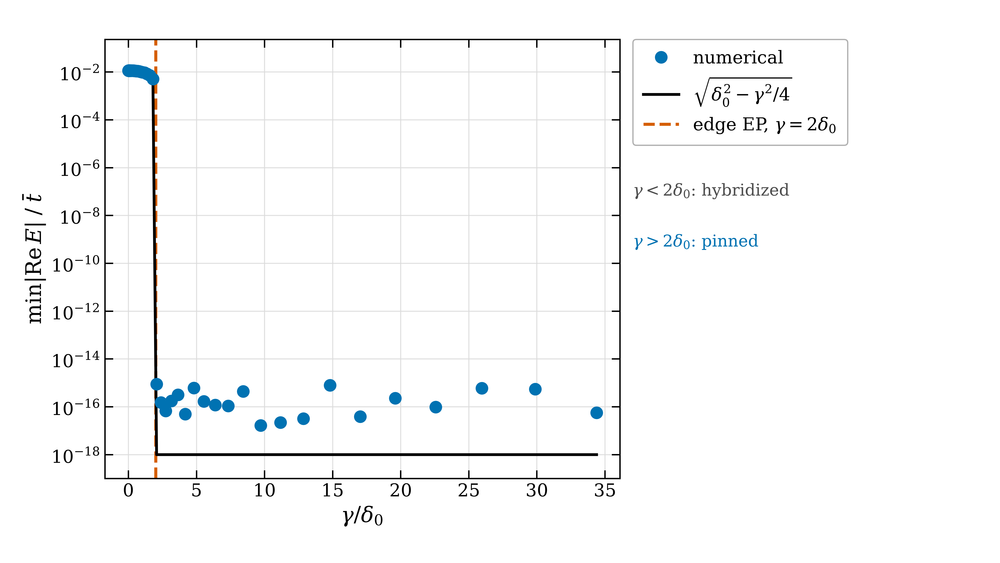

In [13]:
N_EP = 10
delta0 = nt.bare_hybridization(N_EP, T1, T2)
gamma_edge = nt.edge_exceptional_point(N_EP, T1, T2)
gamma_bulk = nt.exceptional_point_threshold(T1, T2)

gam_scan = np.concatenate([[0.0], np.logspace(-4, -0.4, 60)])
observed = np.array([np.min(np.abs(np.linalg.eigvals(nt.build_ssh(N_EP, T1, T2, g)).real))
                     for g in gam_scan])
predicted = nt.two_level_splitting(gam_scan, delta0)

below = gam_scan < gamma_edge
max_err = float(np.max(np.abs(observed[below] - predicted[below]) / delta0))

results["edge_exceptional_point"] = {
    "N": N_EP, "delta0": float(delta0),
    "gamma_EP_edge": float(gamma_edge), "gamma_EP_bulk": float(gamma_bulk),
    "separation_factor": float(gamma_bulk / gamma_edge),
    "max_relative_error_below_EP": max_err,
}
print(f"delta0                     = {delta0:.6e}")
print(f"edge exceptional point     = {gamma_edge:.6e}")
print(f"bulk exceptional point     = {gamma_bulk:.6e}   ({gamma_bulk/gamma_edge:.1f}x larger)")
print(f"two-level model vs numerics= {max_err:.2e} (relative, below threshold)")

F.save(F.fig_edge_exceptional_point(gam_scan, observed, delta0, predicted),
       FIGDIR, "fig12_edge_exceptional_point")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig12_edge_exceptional_point.png", width=760))

### The observable consequence

While the doublet is hybridised its weight is shared between the two ends of the chain, so an
emitter at one boundary sees only half the semi-infinite value. Once loss de-hybridises the
doublet the full weight is restored. The boundary LDOS therefore carries a sharp, parameter-free
signature of the transition: the weight available at a single boundary doubles.

   N   W0 below EP   W0 above EP    ratio
   8      0.280626      0.561309   2.0002
  10      0.278516      0.557088   2.0002
  15      0.277799      0.555653   2.0002
  20      0.277778      0.555612   2.0002
  30      0.277778      0.555611   2.0002

analytic W0 = 0.555556,  half = 0.277778


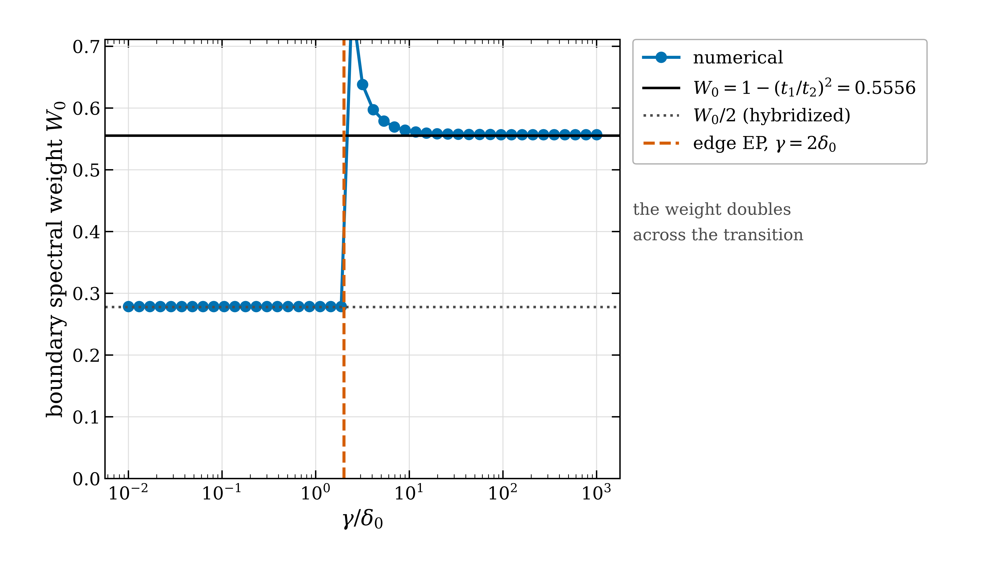

In [14]:
gam_w = np.logspace(-2, 3, 45) * delta0
w0_scan = np.array([nt.edge_mode_spectral_weight(nt.build_ssh(N_EP, T1, T2, g), 0)
                    for g in gam_w])
w0_exact = nt.analytic_edge_weight(T1, T2)

ratios = {}
for n in (8, 10, 15, 20, 30):
    d = nt.bare_hybridization(n, T1, T2)
    lo = nt.edge_mode_spectral_weight(nt.build_ssh(n, T1, T2, 0.01 * d), 0)
    hi = nt.edge_mode_spectral_weight(nt.build_ssh(n, T1, T2, 100 * d), 0)
    ratios[n] = (lo, hi, hi / lo)

results["edge_weight_across_ep"] = {
    "W0_analytic": float(w0_exact),
    "W0_below": float(w0_scan[0]), "W0_above": float(w0_scan[-1]),
    "ratio": float(w0_scan[-1] / w0_scan[0]),
    "ratio_by_N": {str(k): v[2] for k, v in ratios.items()},
}
print(f"{'N':>4} {'W0 below EP':>13} {'W0 above EP':>13} {'ratio':>8}")
for n, (lo, hi, r) in ratios.items():
    print(f"{n:4d} {lo:13.6f} {hi:13.6f} {r:8.4f}")
print(f"\nanalytic W0 = {w0_exact:.6f},  half = {w0_exact/2:.6f}")

F.save(F.fig_edge_weight_vs_gamma(gam_w, w0_scan, delta0, w0_exact),
       FIGDIR, "fig13_edge_weight_vs_gamma")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig13_edge_weight_vs_gamma.png", width=760))

In [15]:
# Just above the edge exceptional point the boundary eigenvectors are close to
# self-orthogonal (psi^T psi -> 0 at coalescence), which enhances the biorthogonal
# residue. This is the transient overshoot visible just above threshold in the
# figure; the residue settles at W0 within about a decade in gamma / delta0.
near_ep = []
for x in (2.05, 3.0, 10.0, 100.0):
    Hx = nt.build_ssh(N_EP, T1, T2, x * delta0)
    ev_x, vr_x = np.linalg.eig(Hx)
    k = nt.find_edge_modes(ev_x, vr_x)["protected_idx"][0]
    psi = vr_x[:, k] / np.linalg.norm(vr_x[:, k])
    near_ep.append({"gamma_over_delta0": x,
                    "weight": float(nt.edge_mode_spectral_weight(Hx, 0)),
                    "abs_psiT_psi": float(abs(np.sum(psi * psi)))})
results["near_ep_residue"] = near_ep
print(f"{'gamma/delta0':>13} {'residue':>9} {'|psi^T psi|':>12}")
for d in near_ep:
    print(f"{d['gamma_over_delta0']:13.2f} {d['weight']:9.4f} {d['abs_psiT_psi']:12.4f}")

 gamma/delta0   residue  |psi^T psi|
         2.05    1.5473       0.2195
         3.00    0.6522       0.7454
        10.00    0.5628       0.9798
       100.00    0.5571       0.9998


### When the condition fails

The threshold involves the *disordered* $\delta_0$, which fluctuates upward, so in very short
chains individual realisations can be pushed back below it. Two independent measures are compared:
the fraction of realisations with $\gamma < 2\delta_0$, and the fraction that actually lose the
pinning. Because the two-level reduction is exact for every bond-disordered realisation, the two must
coincide realisation by realisation; the comparison checks the numerics rather than the model.

In [16]:
frac = {}
for n in (5, 6, 8, 10, 20):
    d = nt.fraction_below_edge_ep(n, T1, T2, GAMMA, 0.4, 300, SEED)
    frac[n] = d
results["fraction_below_ep"] = {str(k): v for k, v in frac.items()}

print(f"{'N':>4} {'predicted below EP':>20} {'observed not pinned':>21}")
for n, d in frac.items():
    print(f"{n:4d} {d['fraction_below_ep']:20.3f} {1 - d['frac_pinned']:21.3f}")

   N   predicted below EP   observed not pinned
   5                0.023                 0.023
   6                0.000                 0.000
   8                0.000                 0.000
  10                0.000                 0.000
  20                0.000                 0.000


---
# 5. Symmetry-resolved disorder protection

Now the two disorder classes established in Section 1 are applied to the observable. The
expectation is that symmetry-preserving bond disorder leaves the real energy pinned while
symmetry-breaking on-site disorder displaces it.

Every measurement is accompanied by a **trivial-phase control**: the same calculation with the
dimerisation reversed. Without it, insensitivity to disorder proves nothing, because a quantity can
be robust simply because a gap is large. Only the disappearance of the effect in the trivial phase
separates topological protection from generic robustness.

The sweep deliberately extends to $W = 1.5\,\bar t$, well past the point where the picture starts to
break down, so the failure is visible rather than hidden beyond the axis.

In [17]:
study = nt.run_disorder_study(N_CELLS, T1, T2, GAMMA, EDGE_SITE, BULK_SITE,
                             GAP_GRID, ETA, W_VALS, ["bond", "on_site"],
                             N_REALIZATIONS, SEED, trivial_t2=TRIVIAL_RATIO * T1)
topo, triv = study["topological"], study["trivial"]
pick = lambda d, k, s: np.array([d[W][k][s] for W in W_VALS])

results["disorder"] = {
    "W_vals": W_VALS,
    "bond_displacement": pick(topo["bond"], "disp", "mean").tolist(),
    "onsite_displacement": pick(topo["on_site"], "disp", "mean").tolist(),
    "onsite_displacement_sem": pick(topo["on_site"], "disp", "sem").tolist(),
    "bond_enhancement": pick(topo["bond"], "enh", "mean").tolist(),
    "bond_enhancement_sem": pick(topo["bond"], "enh", "sem").tolist(),
    "onsite_enhancement": pick(topo["on_site"], "enh", "mean").tolist(),
    "onsite_enhancement_sem": pick(topo["on_site"], "enh", "sem").tolist(),
    "trivial_bond_enhancement": pick(triv["bond"], "enh", "mean").tolist(),
    "trivial_onsite_enhancement": pick(triv["on_site"], "enh", "mean").tolist(),
}

print(f"{'W':>5} {'bond |Re E|':>13} {'on-site |Re E|':>20} {'trivial (on-site)':>18}")
for W in W_VALS:
    b, o, t = topo["bond"][W], topo["on_site"][W], triv["on_site"][W]
    print(f"{W:5.1f} {b['disp']['mean']:13.3e} "
          f"{o['disp']['mean']:11.4f} +/- {o['disp']['sem']:.4f} {t['enh']['mean']:18.3f}")

    W   bond |Re E|       on-site |Re E|  trivial (on-site)
  0.0     4.281e-16      0.0000 +/- 0.0000              1.020
  0.1     7.446e-16      0.0150 +/- 0.0007              1.020
  0.2     6.337e-16      0.0302 +/- 0.0014              1.023
  0.4     6.539e-16      0.0592 +/- 0.0028              1.025
  0.6     6.206e-16      0.0803 +/- 0.0037              1.037
  1.0     6.298e-16      0.1329 +/- 0.0064              1.089
  1.5     7.097e-03      0.2145 +/- 0.0109              1.339


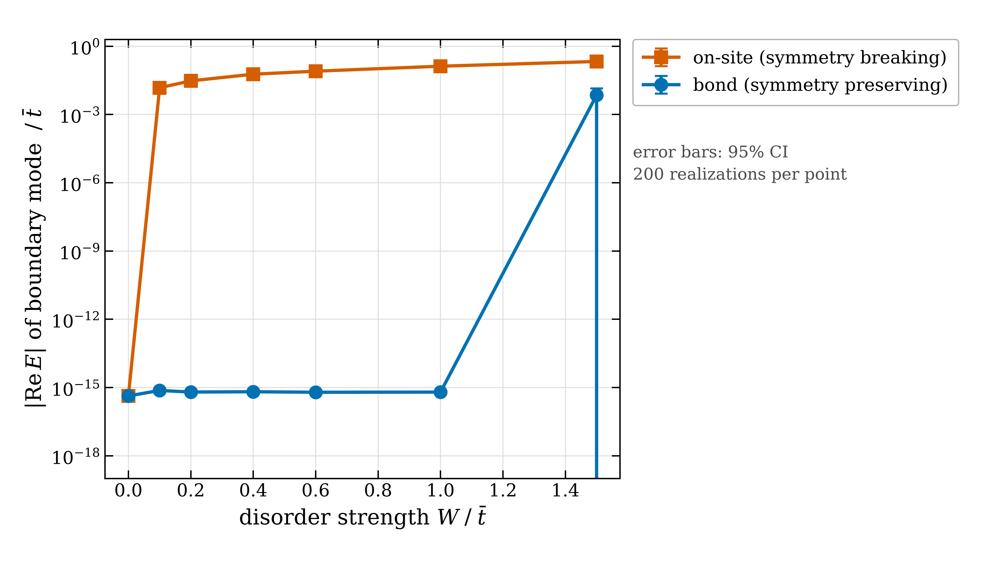

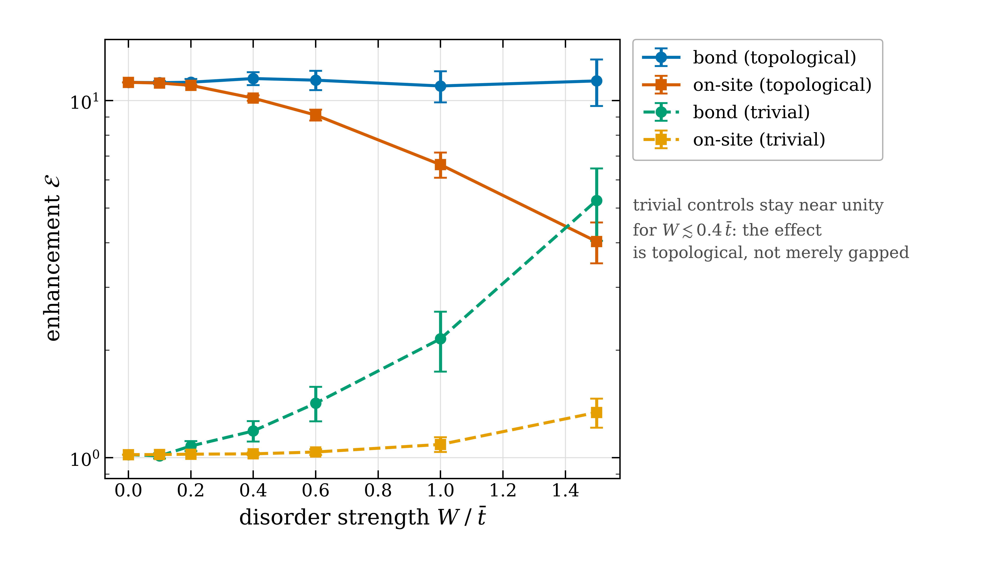

In [18]:
F.save(F.fig_displacement(W_VALS,
                          pick(topo["bond"], "disp", "mean"), pick(topo["bond"], "disp", "ci95"),
                          pick(topo["on_site"], "disp", "mean"), pick(topo["on_site"], "disp", "ci95")),
       FIGDIR, "fig14_displacement")
F.save(F.fig_enhancement_disorder(W_VALS, {
    "bond (topological)":    (pick(topo["bond"], "enh", "mean"), pick(topo["bond"], "enh", "ci95")),
    "on-site (topological)": (pick(topo["on_site"], "enh", "mean"), pick(topo["on_site"], "enh", "ci95")),
    "bond (trivial)":        (pick(triv["bond"], "enh", "mean"), pick(triv["bond"], "enh", "ci95")),
    "on-site (trivial)":     (pick(triv["on_site"], "enh", "mean"), pick(triv["on_site"], "enh", "ci95")),
}), FIGDIR, "fig15_enhancement_disorder")
for name in ("fig14_displacement", "fig15_enhancement_disorder"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

### How far the control can be trusted

The control is only useful while the trivial phase stays featureless. Strong disorder can localise
a state near the boundary by accident, with no topological origin, and such a realisation mimics
exactly the signature the control exists to exclude. The rate at which this happens therefore
bounds the range over which the comparison carries weight, a limitation worth quantifying rather
than assuming away.

Fraction of trivial-phase realisations with an edge-to-bulk ratio above 2.
    W       bond     worst    on-site     worst
  0.0      0.000      1.02      0.000      1.02
  0.1      0.000      1.45      0.000      1.03
  0.2      0.007      2.06      0.000      1.07
  0.4      0.073      4.22      0.000      1.22
  0.6      0.200      8.23      0.000      1.51
  1.0      0.313     20.64      0.040      2.79
  1.5      0.387     35.36      0.153      7.76


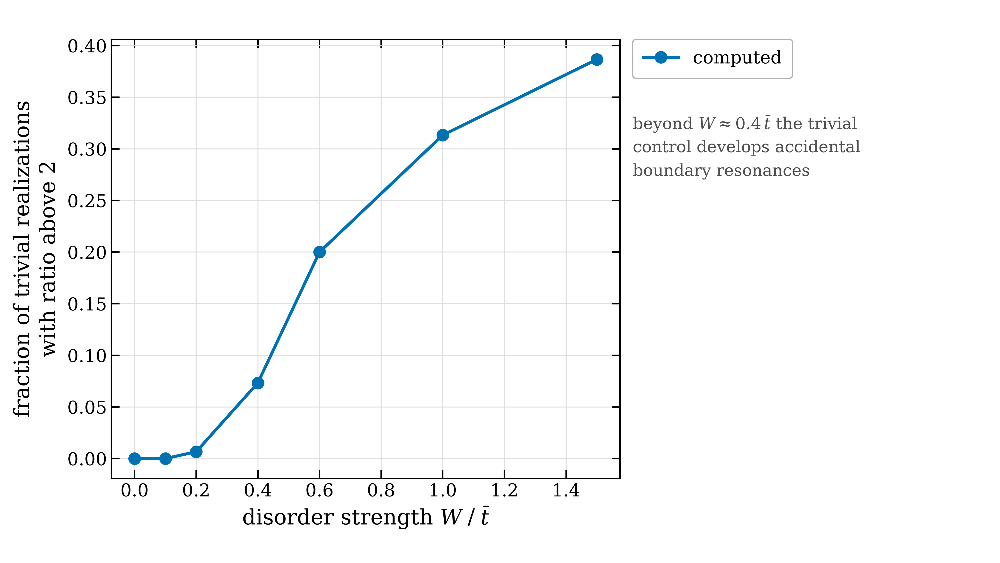

In [19]:
anom = nt.trivial_control_anomalies(N_CELLS, T1, TRIVIAL_RATIO * T1, GAMMA,
                                    W_VALS, EDGE_SITE, BULK_SITE, GAP_GRID, ETA,
                                    150, SEED, threshold=2.0)
results["trivial_control_anomalies"] = {
    "W_vals": W_VALS, "threshold": 2.0,
    "bond_rate": anom["bond"]["anomaly_rate"],
    "bond_max": anom["bond"]["max_enhancement"],
    "onsite_rate": anom["on_site"]["anomaly_rate"],
    "onsite_max": anom["on_site"]["max_enhancement"],
}
print("Fraction of trivial-phase realisations with an edge-to-bulk ratio above 2.")
print(f"{'W':>5} {'bond':>10} {'worst':>9} {'on-site':>10} {'worst':>9}")
for i, W in enumerate(W_VALS):
    print(f"{W:5.1f} {anom['bond']['anomaly_rate'][i]:10.3f} "
          f"{anom['bond']['max_enhancement'][i]:9.2f} "
          f"{anom['on_site']['anomaly_rate'][i]:10.3f} "
          f"{anom['on_site']['max_enhancement'][i]:9.2f}")

F.save(F.fig_convergence(W_VALS, anom["bond"]["anomaly_rate"],
                         r"disorder strength $W \;/\; \bar{t}$",
                         "fraction of trivial realizations\nwith ratio above 2",
                         note="beyond $W \\approx 0.4\\,\\bar{t}$ the trivial\ncontrol develops accidental\nboundary resonances",
                         logx=False),
       FIGDIR, "fig16_trivial_control_anomalies")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig16_trivial_control_anomalies.png", width=760))

---
# 6. Parameter dependence and what loss costs

Loss has now been shown to stabilise the position of the boundary mode. It remains to quantify what
it costs, which is the magnitude of the response.

Enhancement at t2/t1 = 1.5 (the operating point):
  gamma = 0.0 tbar  ->  E =  68.51
  gamma = 0.1 tbar  ->  E =  24.32
  gamma = 0.3 tbar  ->  E =  11.25
  gamma = 0.5 tbar  ->  E =   7.67
  gamma = 0.8 tbar  ->  E =   5.47

attenuation from gamma = 0 to gamma = 0.3 : 6.09x
map column t2/t1 = 1.5 vs direct calculation : 0.0e+00 (relative)


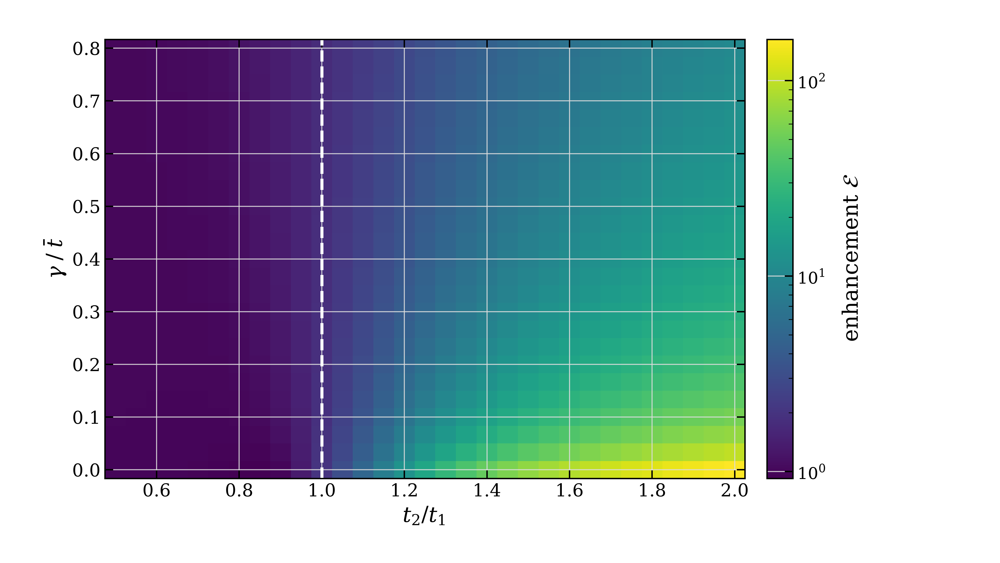

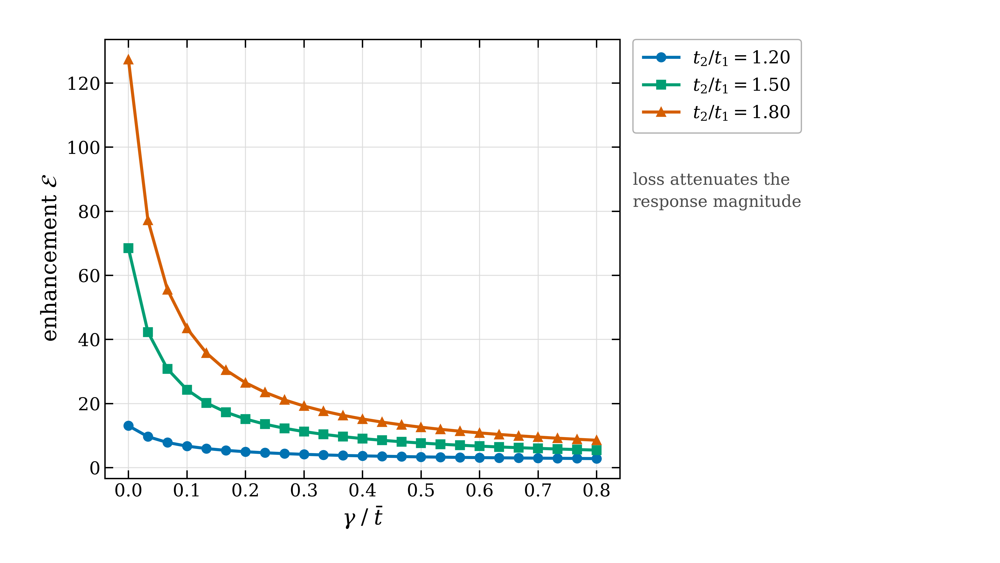

In [20]:
# The map is computed along the line (t1 + t2)/2 = 1, so the energy unit, the
# loss rate, the broadening and the gap window mean the same thing at every
# ratio and the map passes exactly through the operating point (t2/t1 = 1.5).
# Both grids contain the ratios and loss rates quoted in the text.
r_vals = np.linspace(0.5, 2.0, 31)          # step 0.05: contains 1.2, 1.5, 1.8
g_vals = np.linspace(0.0, 0.8, 25)          # step 1/30: contains 0.1, 0.3, 0.5, 0.8
enh_map = nt.enhancement_map(N_CELLS, r_vals, g_vals, GAP_GRID, ETA, mean_hopping=TBAR)

slice_gamma = {g: float(nt.enhancement_factor(nt.build_ssh(N_CELLS, T1, 1.5*T1, g),
                                              EDGE_SITE, BULK_SITE, GAP_GRID, ETA))
               for g in (0.0, 0.1, 0.3, 0.5, 0.8)}
results["enhancement_vs_gamma"] = slice_gamma
results["attenuation_factor"] = slice_gamma[0.0] / slice_gamma[0.3]

# The t2/t1 = 1.5 column of the map is the operating point itself.
i15 = int(np.argmin(np.abs(r_vals - 1.5)))
map_check = max(abs(enh_map[int(np.argmin(np.abs(g_vals - g))), i15] - v) / v
                for g, v in slice_gamma.items())
idx = [int(np.argmin(np.abs(r_vals - x))) for x in (1.2, 1.5, 1.8)]
results["enhancement_map"] = {
    "parametrisation": "(t1 + t2)/2 = 1",
    "r_vals": r_vals.tolist(), "gamma_vals": g_vals.tolist(),
    "slices": {f"{r_vals[i]:.2f}": enh_map[:, i].tolist() for i in idx},
    "operating_point_consistency": float(map_check),
}

print("Enhancement at t2/t1 = 1.5 (the operating point):")
for g, v in slice_gamma.items():
    print(f"  gamma = {g:.1f} tbar  ->  E = {v:6.2f}")
print(f"\nattenuation from gamma = 0 to gamma = 0.3 : {results['attenuation_factor']:.2f}x")
print(f"map column t2/t1 = 1.5 vs direct calculation : {map_check:.1e} (relative)")

F.save(F.fig_map(r_vals, g_vals, enh_map, r"enhancement $\mathcal{E}$", log_color=True),
       FIGDIR, "fig17_enhancement_map")
F.save(F.fig_gamma_slices(g_vals, [enh_map[:, i] for i in idx],
                          [f"{r_vals[i]:.2f}" for i in idx]),
       FIGDIR, "fig18_gamma_slices")
for name in ("fig17_enhancement_map", "fig18_gamma_slices"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

---
# 7. Numerical validation

The central claim of Section 3 is that a quantity is pinned at $10^{-16}$ rather than $10^{-4}$.
A statement at that level is only worth making if the numerics are demonstrably trustworthy, so
every spectral quantity is computed by independent routes and every reported number is checked
against the numerical parameters that produced it.

Green function vs eigendecomposition : 2.931e-14   (same operator, two algorithms)
Green function vs semi-infinite      : 2.251e-05   (finite-size boundary correction)
in-gap states, open boundaries       : 2
in-gap states, periodic boundaries   : 0


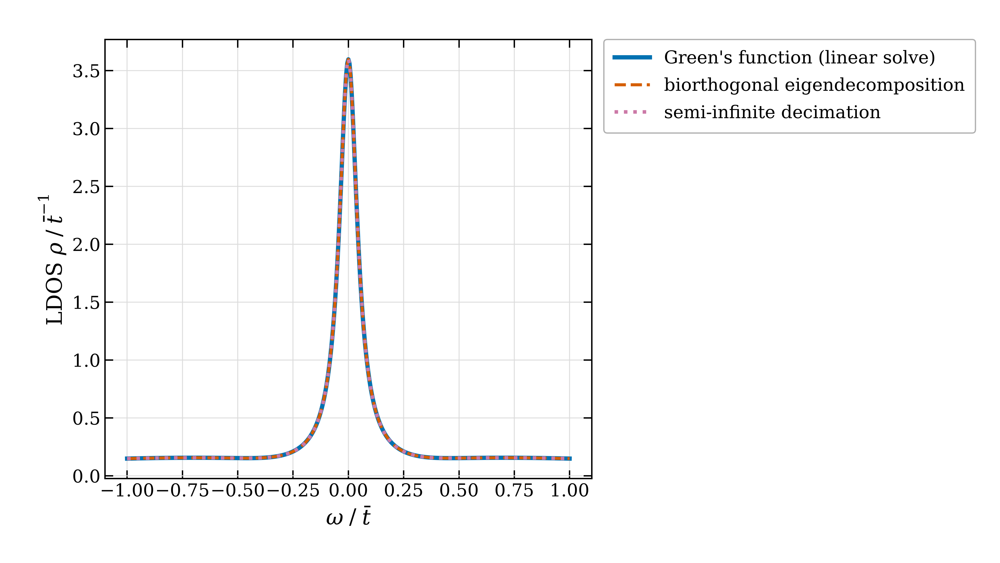

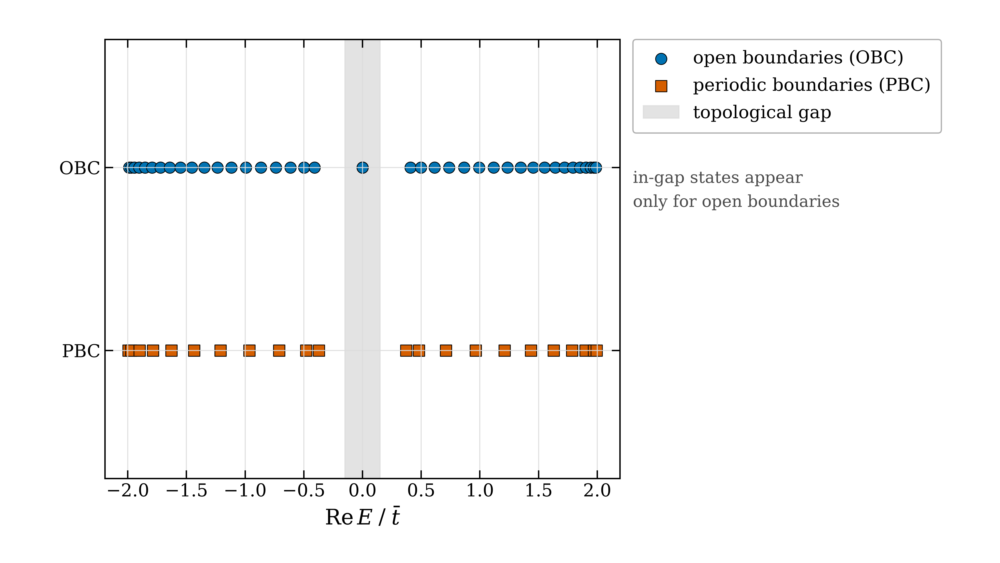

In [21]:
om_v = np.linspace(-1.0, 1.0, 401)
gf = nt.ldos_spectrum(H, EDGE_SITE, om_v, ETA)
ed = np.array([nt.ldos_eigdecomp(H, EDGE_SITE, w, ETA) for w in om_v])
sf = nt.surface_ldos_spectrum(om_v, T1, T2, GAMMA, ETA, sublattice=0)

evals_pbc = np.linalg.eigvals(nt.build_ssh_pbc(N_CELLS, T1, T2, GAMMA))
results["cross_validation"] = {
    "gf_vs_eigendecomposition": float(np.max(np.abs(gf - ed))),
    "gf_vs_semi_infinite": float(np.max(np.abs(gf - sf))),
    "in_gap_states_obc": int(np.sum(np.abs(evals.real) < GAP_HW)),
    "in_gap_states_pbc": int(np.sum(np.abs(evals_pbc.real) < GAP_HW)),
}
print(f"Green function vs eigendecomposition : {results['cross_validation']['gf_vs_eigendecomposition']:.3e}"
      "   (same operator, two algorithms)")
print(f"Green function vs semi-infinite      : {results['cross_validation']['gf_vs_semi_infinite']:.3e}"
      "   (finite-size boundary correction)")
print(f"in-gap states, open boundaries       : {results['cross_validation']['in_gap_states_obc']}")
print(f"in-gap states, periodic boundaries   : {results['cross_validation']['in_gap_states_pbc']}")

F.save(F.fig_cross_validation(om_v, gf, ed, sf), FIGDIR, "fig19_cross_validation")
F.save(F.fig_obc_vs_pbc(evals, evals_pbc, GAP_HW), FIGDIR, "fig20_obc_vs_pbc")
for name in ("fig19_cross_validation", "fig20_obc_vs_pbc"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

sum rule, widest window : 1.000033
sum rule, per-site range: 0.994425 to 0.999203
enhancement, coarse->fine grid : 11.247106 -> 11.247335
ensemble 95% CI, 5 -> 200 realisations : 1.516 -> 0.165


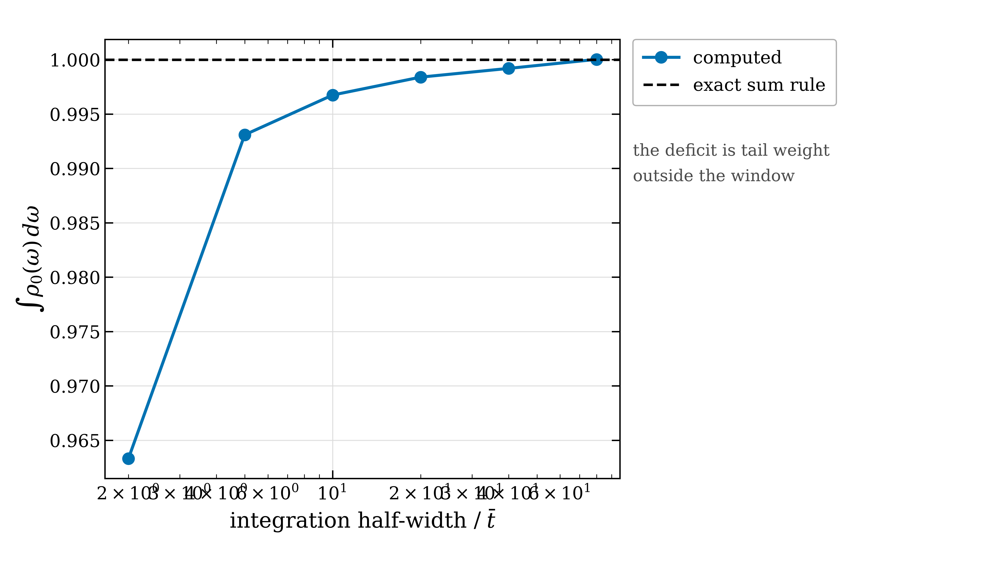

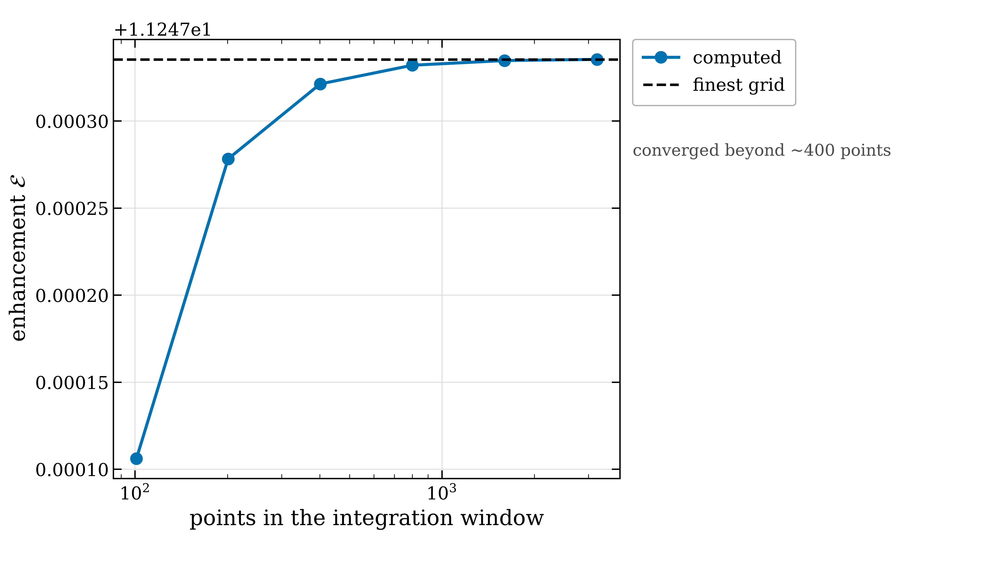

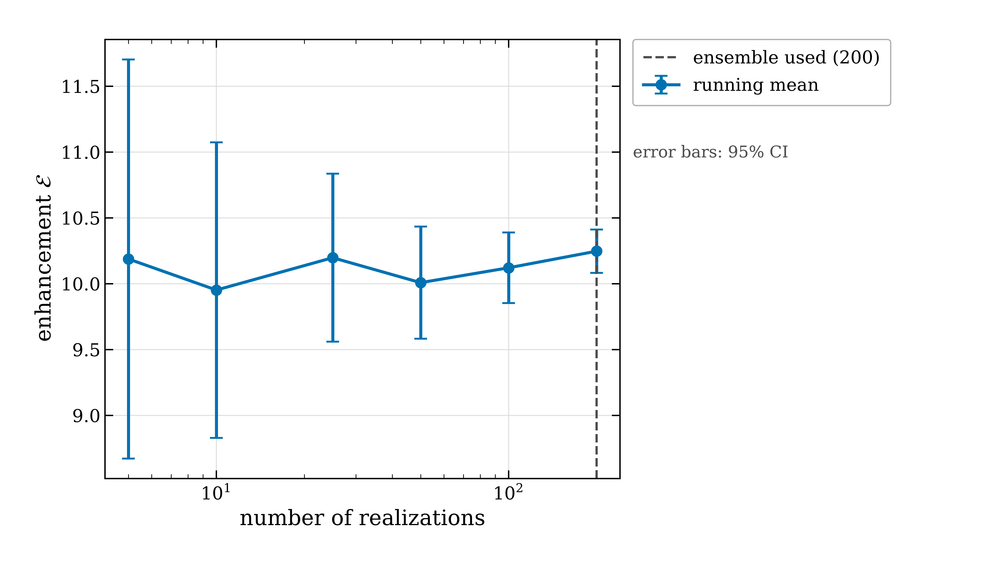

In [22]:
# Spectral sum rule: the exact value is 1 per site, and a finite window falls
# short only by the Lorentzian tail weight lying outside it.
windows = [2.0, 5.0, 10.0, 20.0, 40.0, 80.0]
sum_rule = [nt.ldos_sum_rule(H, EDGE_SITE, np.linspace(-w, w, 4001), ETA) for w in windows]
per_site = nt.ldos_sum_rule_all_sites(H, np.linspace(-40, 40, 8001), ETA)

# Integration grid and ensemble size.
grids = [101, 201, 401, 801, 1601, 3201]
enh_grid = [float(nt.enhancement_factor(H, EDGE_SITE, BULK_SITE,
                                        np.linspace(-GAP_HW, GAP_HW, m), ETA)) for m in grids]
ens = nt.ensemble_convergence(N_CELLS, T1, T2, GAMMA, 0.4, "on_site", EDGE_SITE,
                              BULK_SITE, GAP_GRID, ETA, N_REALIZATIONS, SEED)

results["sum_rule"] = {"half_widths": windows, "values": sum_rule,
                       "per_site_min": per_site["min"], "per_site_max": per_site["max"]}
results["grid_convergence"] = {"n_omega": grids, "enhancement": enh_grid}
results["ensemble_convergence"] = ens

print(f"sum rule, widest window : {sum_rule[-1]:.6f}")
print(f"sum rule, per-site range: {per_site['min']:.6f} to {per_site['max']:.6f}")
print(f"enhancement, coarse->fine grid : {enh_grid[0]:.6f} -> {enh_grid[-1]:.6f}")
print(f"ensemble 95% CI, 5 -> {N_REALIZATIONS} realisations : "
      f"{ens['ci95'][0]:.3f} -> {ens['ci95'][-1]:.3f}")

F.save(F.fig_convergence(windows, sum_rule, r"integration half-width $/\; \bar{t}$",
                         r"$\int \rho_0(\omega)\,d\omega$",
                         note="the deficit is tail weight\noutside the window",
                         reference=1.0, ref_label="exact sum rule"),
       FIGDIR, "fig21_sum_rule")
F.save(F.fig_convergence(grids, enh_grid, "points in the integration window",
                         r"enhancement $\mathcal{E}$", note="converged beyond ~400 points",
                         reference=enh_grid[-1], ref_label="finest grid"),
       FIGDIR, "fig22_grid_convergence")
F.save(F.fig_ensemble_convergence(ens["checkpoints"], ens["mean"], ens["ci95"],
                                  r"enhancement $\mathcal{E}$", n_used=N_REALIZATIONS),
       FIGDIR, "fig23_ensemble_convergence")
for name in ("fig21_sum_rule", "fig22_grid_convergence", "fig23_ensemble_convergence"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

---
# 8. Full-wave electromagnetic validation

Everything so far is tight binding. The remaining question is whether the picture survives in a
real dielectric structure, where there are no hoppings, only Maxwell's equations.

## Method

For transverse-magnetic polarisation the fields reduce to a single component $E_z$ obeying the
scalar Helmholtz equation

$$\nabla^2 E_z + \omega^2 \varepsilon(x, y) E_z = -S ,$$

in units with $c = \varepsilon_0 = \mu_0 = 1$. Lengths are in units of the mean lattice period $a$
and frequencies are quoted as $a/\lambda = \omega/2\pi$. Outgoing boundaries are imposed by complex
coordinate stretching, $s(x) = 1 + i\sigma(x)/\omega$ with a polynomial conductivity profile, and
the resulting sparse system is factorised directly.

A unit line source at $\mathbf{r}_0$ produces, in a homogeneous medium,
$E_z(\mathbf r) = \tfrac{i}{4}H_0^{(1)}(\omega\sqrt{\varepsilon}\,|\mathbf r - \mathbf r_0|)$.
The real part diverges logarithmically at the source, but the imaginary part is finite,
$\mathrm{Im}\,E_z(\mathbf r_0) = 1/4$, and it is what fixes the radiated power. The Purcell factor
is that quantity normalised to its homogeneous value; taking the ratio on the same grid also
cancels the grid-dependent part of the self-field.

## Structure

Silicon-like rods ($\varepsilon = 12$, radius $0.15\,a$) in air, dimerised with centre-to-centre
spacings $0.6\,a$ within and $0.4\,a$ between unit cells. The smaller inter-cell spacing makes the
evanescent inter-cell coupling the stronger one, which places the chain in the topological phase.
No coupling ratio is extracted from the full-wave solution, so the comparison with the lattice model
is qualitative. Material loss $\mathrm{Im}\,\varepsilon$ is applied to the $B$ rods only, the direct
analogue of sublattice-selective loss. Emitters sit at the centres of the outermost and the central
$A$ rods, both lossless.

The trivial control exchanges the two gaps. It has the same period and therefore the same bulk
bands, differing only in how the chain terminates, so any difference between the two is a boundary
effect and not a difference in bulk optical response.

### Verification against the analytic Green function

Before trusting the solver on the structure, it is checked against the exact result in a
homogeneous medium: the Purcell factor must be unity and the radial field profile must follow the
Hankel function. Both errors should fall as $h^2$ for a second-order discretisation.

 points per a    Purcell     |F - 1|   profile error
           20    1.00111    1.11e-03        1.07e-03
           30    1.00049    4.93e-04        4.72e-04
           40    1.00028    2.78e-04        2.65e-04
           60    1.00012    1.23e-04        1.18e-04

error reduction 9.0x for an 9.0x change in h^2: second-order, as expected


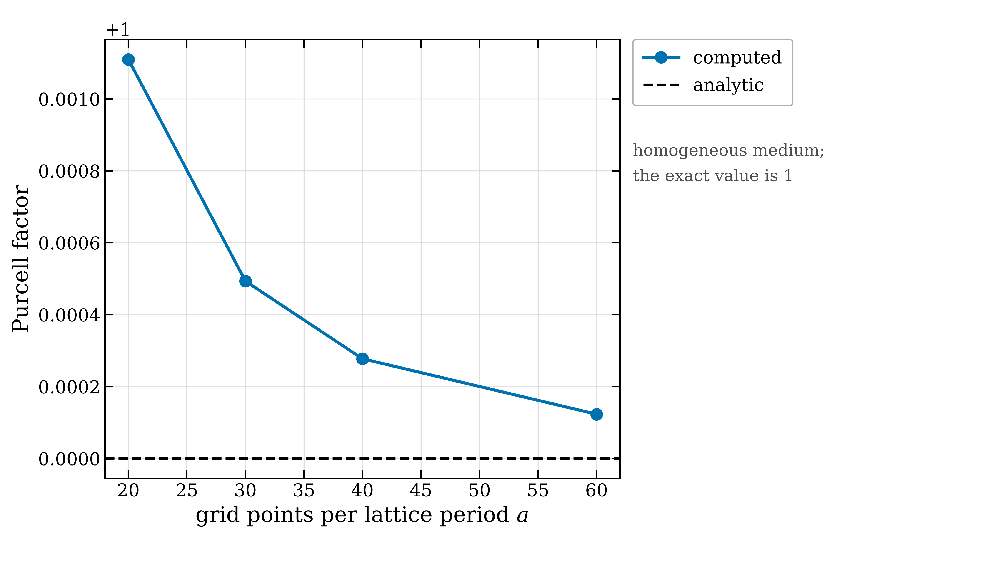

In [23]:
bench = em.validate_homogeneous_medium()
results["fdfd_benchmark"] = bench

print(f"{'points per a':>13} {'Purcell':>10} {'|F - 1|':>11} {'profile error':>15}")
for res, p, pe, fe in zip(bench["resolutions"], bench["purcell"],
                          bench["purcell_error"], bench["profile_error"]):
    print(f"{res:13d} {p:10.5f} {pe:11.2e} {fe:15.2e}")

ratio = bench["purcell_error"][0] / bench["purcell_error"][-1]
scale = (bench["spacings"][0] / bench["spacings"][-1]) ** 2
print(f"\nerror reduction {ratio:.1f}x for an {scale:.1f}x change in h^2: second-order, as expected")

F.save(F.fig_convergence(bench["resolutions"], bench["purcell"],
                         "grid points per lattice period $a$", "Purcell factor",
                         note="homogeneous medium;\nthe exact value is 1",
                         logx=False, reference=1.0, ref_label="analytic"),
       FIGDIR, "fig24_fdfd_benchmark")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig24_fdfd_benchmark.png", width=760))

In [24]:
t0 = time.time()
em_study = em.photonic_ldos_study(n_cells=8, loss_b=0.0, resolution=32, n_freq=31)
print(f"({time.time() - t0:.0f} s)")

results["photonic_validation"] = {
    "frequencies": em_study["frequencies"].tolist(),
    "gap_window": list(em.GAP_WINDOW),
    "topological": {k: (v.tolist() if isinstance(v, np.ndarray) else v)
                    for k, v in em_study["topological"].items()},
    "trivial": {k: (v.tolist() if isinstance(v, np.ndarray) else v)
                for k, v in em_study["trivial"].items()},
}
for phase in ("topological", "trivial"):
    d = em_study[phase]
    print(f"{phase:12s}: gap-averaged enhancement {d['gap_enhancement']:6.3f}"
          f" | peak edge {d['peak_edge']:5.3f} at a/lambda = {d['peak_frequency']:.4f}")
contrast = (em_study["topological"]["gap_enhancement"]
            / em_study["trivial"]["gap_enhancement"])
results["photonic_validation"]["topological_over_trivial"] = float(contrast)
print(f"\ntopological / trivial = {contrast:.2f}")

(82 s)
topological : gap-averaged enhancement  7.882 | peak edge 5.598 at a/lambda = 0.2867
trivial     : gap-averaged enhancement  0.692 | peak edge 4.204 at a/lambda = 0.3310

topological / trivial = 11.39


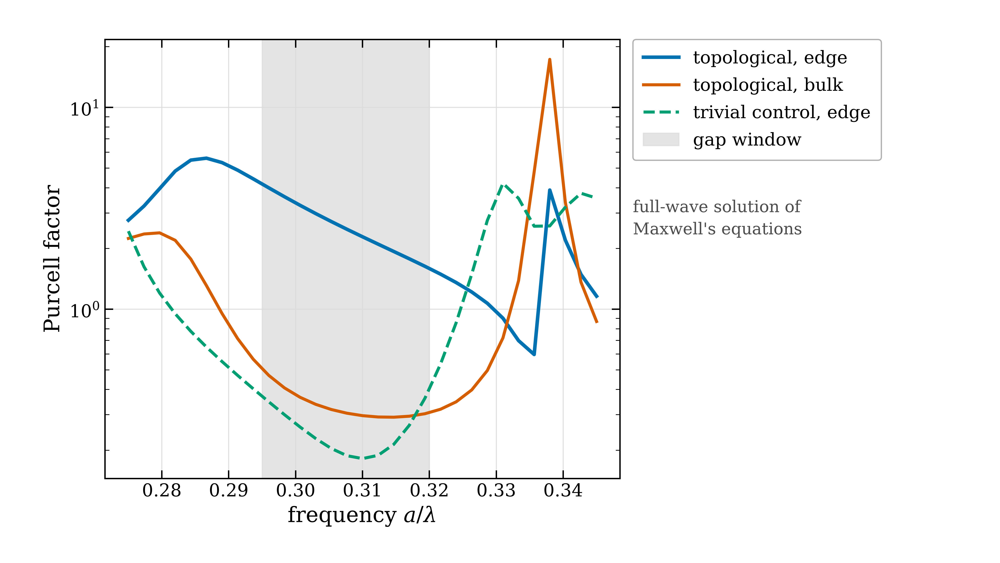

In [25]:
freqs = em_study["frequencies"]
fig, ax = F._new()
ax.plot(freqs, em_study["topological"]["edge"], "-", color=F.C["edge"],
        linewidth=2.8, label="topological, edge")
ax.plot(freqs, em_study["topological"]["bulk"], "-", color=F.C["bulk"],
        linewidth=2.4, label="topological, bulk")
ax.plot(freqs, em_study["trivial"]["edge"], "--", color=F.C["topo"],
        linewidth=2.4, label="trivial control, edge")
ax.axvspan(*em.GAP_WINDOW, color=F.C["grid"], alpha=0.75, zorder=0,
           label="gap window")
ax.set_xlabel(r"frequency $a/\lambda$")
ax.set_ylabel("Purcell factor")
ax.set_yscale("log")
F._legend_right(ax)
F._note(fig, "full-wave solution of\nMaxwell's equations")
F.save(fig, FIGDIR, "fig25_photonic_spectra")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig25_photonic_spectra.png", width=760))

### Loss dependence and convergence

Two final checks: that material loss attenuates the enhancement in the full-wave structure as it
does in the lattice model, and that the reported ratio is converged in the grid resolution. The loss
series uses the same frequency grid and the same gap window as the spectra above, so its zero-loss
point reproduces the gap-averaged enhancement of the topological chain exactly.

(167 s)
  Im eps   gap enhancement   peak edge  at a/lambda
    0.00             7.882       5.598       0.2867
    0.50             3.875       5.319       0.2867
    1.00             2.603       5.107       0.2867
    2.00             1.619       4.794       0.2867
attenuation over the range : 4.87x

 points per a      edge      bulk     ratio
           16    3.3659    0.3711     9.070
           20    3.4141    0.3782     9.027
           24    3.4713    0.4100     8.467
           32    3.3611    0.3758     8.944
spread across resolutions : 6.8%


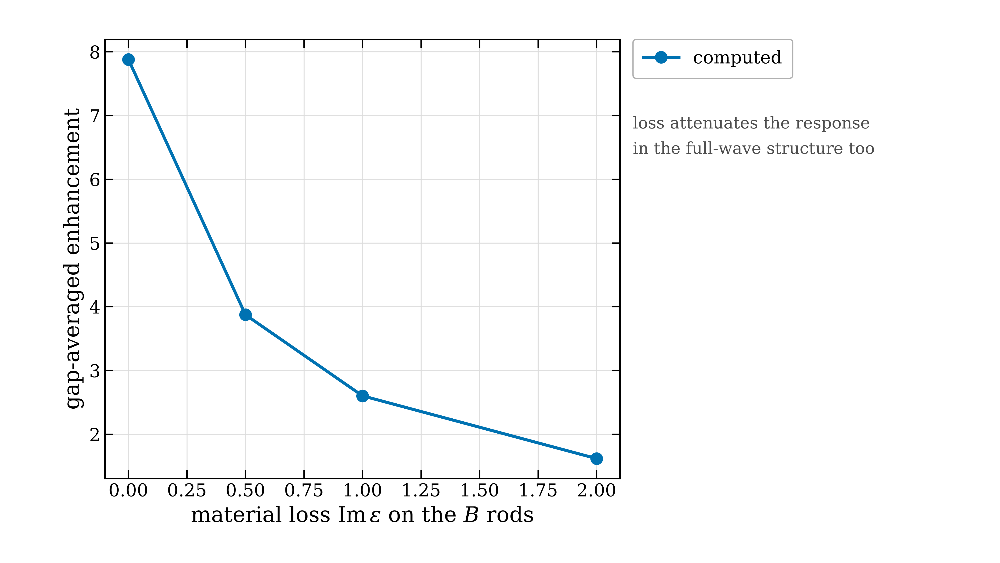

In [26]:
t0 = time.time()
# Same frequency grid and gap window as the spectra above, so the zero-loss
# point reproduces the gap-averaged enhancement of the topological chain.
loss_series = em.photonic_loss_series([0.0, 0.5, 1.0, 2.0], n_cells=8,
                                      resolution=32, n_freq=31)
em_conv = em.photonic_resolution_convergence()
print(f"({time.time() - t0:.0f} s)")

results["photonic_loss_series"] = {k: v.tolist() for k, v in loss_series.items()}
results["photonic_resolution_convergence"] = em_conv

print(f"{'Im eps':>8} {'gap enhancement':>17} {'peak edge':>11} {'at a/lambda':>12}")
for a, b, c, f in zip(loss_series["loss_values"], loss_series["gap_enhancement"],
                      loss_series["peak_edge"], loss_series["peak_frequency"]):
    print(f"{a:8.2f} {b:17.3f} {c:11.3f} {f:12.4f}")
assert abs(loss_series["gap_enhancement"][0]
           - em_study["topological"]["gap_enhancement"]) < 1e-9
print(f"attenuation over the range : "
      f"{loss_series['gap_enhancement'][0] / loss_series['gap_enhancement'][-1]:.2f}x")
print()
print(f"{'points per a':>13} {'edge':>9} {'bulk':>9} {'ratio':>9}")
for a, b, c, d in zip(em_conv["resolutions"], em_conv["edge"], em_conv["bulk"], em_conv["ratio"]):
    print(f"{a:13d} {b:9.4f} {c:9.4f} {d:9.3f}")
spread = (max(em_conv["ratio"]) - min(em_conv["ratio"])) / np.mean(em_conv["ratio"])
results["photonic_resolution_convergence"]["spread"] = float(spread)
print(f"spread across resolutions : {100*spread:.1f}%")

F.save(F.fig_convergence(loss_series["loss_values"], loss_series["gap_enhancement"],
                         r"material loss $\mathrm{Im}\,\varepsilon$ on the $B$ rods",
                         "gap-averaged enhancement",
                         note="loss attenuates the response\nin the full-wave structure too",
                         logx=False),
       FIGDIR, "fig26_photonic_loss")
display(__import__("IPython").display.Image(f"{FIGDIR}/fig26_photonic_loss.png", width=760))

---
# 9. Results

Every figure has been written to `figures/` and every number to `results/results.json`. The
consolidated summary follows, together with an independent audit of the figure set.

In [27]:
with open(os.path.join(RESDIR, "results.json"), "w") as fh:
    json.dump(results, fh, indent=2, default=float)

problems = F.audit_directory(FIGDIR)
n_fig = len([f for f in os.listdir(FIGDIR) if f.endswith(".pdf")])
print(f"{n_fig} figures written to {FIGDIR}/ (vector PDF and 400 dpi PNG)")
print("figure audit:", "all checks passed" if not problems else problems)

26 figures written to figures/ (vector PDF and 400 dpi PNG)
figure audit: all checks passed


In [28]:
w = 46
def row(label, value):
    print(f"  {label:<{w}} {value}")

print("=" * 74)
print("SYMMETRY CLASSIFICATION")
print("=" * 74)
row("Hermitian chiral residual ||sz H sz + H||",
    f"{results['symmetry']['chiral_residual']:.6f}  (= 2 gamma)")
row("CS-dagger residual ||sz H~ sz + H~^dag||",
    f"{results['symmetry']['cs_dagger_residual']:.3e}")
row("spectrum closed under E -> -E*",
    f"{results['symmetry']['spectral_symmetry']:.3e}")
row("eigenvalues pinned at Re E = 0", results["symmetry"]["n_pinned"])

print("\n" + "=" * 74)
print("BOUNDARY MODES AND THE LDOS")
print("=" * 74)
pe = results["edge_modes"]["protected_E"]; le = results["edge_modes"]["lossy_E"]
row("protected mode", f"Re E = {pe[0]:+.2e}, Im E = {pe[1]:+.3e}")
row("lossy mode", f"Re E = {le[0]:+.2e}, Im E = {le[1]:+.7f}")
row("peak edge LDOS / bulk LDOS in gap",
    f"{results['ldos']['peak_edge']:.4f} / {results['ldos']['bulk_at_zero']:.4f} tbar^-1")
row("enhancement at eta = 0.05 tbar", f"{results['ldos']['enhancement']:.4f}")
row("boundary weight W0, numeric / analytic",
    f"{results['ldos']['W0_numeric']:.6f} / {results['ldos']['W0_analytic']:.6f}")
row("LDOS positivity minimum", f"{results['ldos']['positivity_minimum']:+.3e}")

print("\n" + "=" * 74)
print("LOSS-SUPPRESSED HYBRIDISATION")
print("=" * 74)
hs = np.array(results["hybridisation_vs_disorder"]["splitting"])
row("Hermitian splitting, W = 0 to 1.0 tbar", f"{hs[0][0]:.2e} to {hs[0][-1]:.2e}")
row("lossy splitting, same ensembles", f"{hs[1][0]:.2e} to {hs[1][-1]:.2e}")
row("separation", f"{hs[0][-1]/hs[1][-1]:.1e}x")
row("delta0 decay length, fitted / analytic",
    f"{results['delta0_scaling']['xi_fit']:.4f} / "
    f"{results['delta0_scaling']['xi_analytic']:.4f} "
    f"({100*results['delta0_scaling']['rel_error']:.2f}%)")

print("\n" + "=" * 74)
print("EDGE EXCEPTIONAL POINT")
print("=" * 74)
ep = results["edge_exceptional_point"]
row("delta0 at N = 10", f"{ep['delta0']:.6e}")
row("edge exceptional point 2 delta0", f"{ep['gamma_EP_edge']:.6e}")
row("bulk exceptional point 2|t2 - t1|",
    f"{ep['gamma_EP_bulk']:.6e}  ({ep['separation_factor']:.1f}x larger)")
row("two-level model vs full spectrum",
    f"{ep['max_relative_error_below_EP']:.2e} relative")
row("boundary weight ratio across the EP",
    f"{results['edge_weight_across_ep']['ratio']:.4f}")

print("\n" + "=" * 74)
print("DISORDER PROTECTION")
print("=" * 74)
d = results["disorder"]
row("bond disorder displacement, all W",
    f"{min(d['bond_displacement']):.1e} to {max(d['bond_displacement']):.1e}")
row("on-site displacement, W = 0.1 to 1.5 tbar",
    f"{d['onsite_displacement'][1]:.4f} to {d['onsite_displacement'][-1]:.4f}")
row("enhancement under bond disorder",
    f"{d['bond_enhancement'][0]:.2f} to {d['bond_enhancement'][-1]:.2f}")
row("enhancement under on-site disorder",
    f"{d['onsite_enhancement'][0]:.2f} to {d['onsite_enhancement'][-1]:.2f}")
tca = results["trivial_control_anomalies"]
row("trivial control reliable up to",
    f"W = {max(W for W, r in zip(tca['W_vals'], tca['bond_rate']) if r < 0.05):.1f} tbar")

print("\n" + "=" * 74)
print("NUMERICAL VALIDATION")
print("=" * 74)
cv = results["cross_validation"]
row("Green function vs eigendecomposition", f"{cv['gf_vs_eigendecomposition']:.2e}")
row("Green function vs semi-infinite", f"{cv['gf_vs_semi_infinite']:.2e}")
row("in-gap states, open / periodic",
    f"{cv['in_gap_states_obc']} / {cv['in_gap_states_pbc']}")
row("sum rule, widest window", f"{results['sum_rule']['values'][-1]:.6f}")
row("localisation length at N = 60",
    f"{results['localization_convergence']['xi_fit'][-1]:.4f} "
    f"({100*results['localization_convergence']['rel_error'][-1]:.2f}%)")

print("\n" + "=" * 74)
print("FULL-WAVE ELECTROMAGNETIC VALIDATION")
print("=" * 74)
pv = results["photonic_validation"]
row("solver benchmark, finest grid",
    f"Purcell = {results['fdfd_benchmark']['purcell'][-1]:.5f} (exact 1)")
row("topological, gap-averaged enhancement",
    f"{pv['topological']['gap_enhancement']:.3f}")
row("trivial control, same quantity", f"{pv['trivial']['gap_enhancement']:.3f}")
row("topological / trivial", f"{pv['topological_over_trivial']:.2f}")
row("attenuation with material loss",
    f"{results['photonic_loss_series']['gap_enhancement'][0] / results['photonic_loss_series']['gap_enhancement'][-1]:.2f}x")
row("resolution spread of the ratio",
    f"{100*results['photonic_resolution_convergence']['spread']:.1f}%")
print("=" * 74)

SYMMETRY CLASSIFICATION
  Hermitian chiral residual ||sz H sz + H||      0.600000  (= 2 gamma)
  CS-dagger residual ||sz H~ sz + H~^dag||       0.000e+00
  spectrum closed under E -> -E*                 6.884e-15
  eigenvalues pinned at Re E = 0                 2

BOUNDARY MODES AND THE LDOS
  protected mode                                 Re E = +4.28e-16, Im E = -1.340e-07
  lossy mode                                     Re E = +3.66e-16, Im E = -0.2999999
  peak edge LDOS / bulk LDOS in gap              3.5964 / 0.1326 tbar^-1
  enhancement at eta = 0.05 tbar                 11.2467
  boundary weight W0, numeric / analytic         0.555557 / 0.555556
  LDOS positivity minimum                        +1.082e-02

LOSS-SUPPRESSED HYBRIDISATION
  Hermitian splitting, W = 0 to 1.0 tbar         2.00e-04 to 2.84e-04
  lossy splitting, same ensembles                3.66e-16 to 2.23e-16
  separation                                     1.3e+12x
  delta0 decay length, fitted / analytic         

---
## Conclusions

The Hermitian chiral relation does not hold for a chain with loss on one sublattice; the shifted
operator obeys the non-Hermitian chiral symmetry CS$^\dagger$ instead, and that relation pins the real
energy of a boundary mode while leaving its decay rate free. Because a mode can only leave the
imaginary axis in company with a partner at equal decay rate, and loss removes the partner,
sublattice loss closes the finite-size hybridisation channel that limits topological protection in
short chains.

Because the Hermitian part anticommutes with $\sigma_z$ for every real bond configuration, the
shifted Hamiltonian squares to $H_0^2 - (\gamma/2)^2$, and the boundary doublet is an exact two-level
system with its own exceptional point at $\gamma = 2\delta_0$, exponentially smaller than the bulk one. Crossing it pins the real energy to
machine precision and doubles the boundary spectral weight. A full-wave solution of Maxwell's
equations reproduces the picture in a dielectric rod chain: the enhancement is present in the
topological geometry, absent in the trivial control, and attenuated by material loss.

Dissipation is therefore not simply detrimental to a topological boundary mode. It costs roughly a
factor of six in the magnitude of the boundary response, and buys exact pinning of its position
along with a factor of two in the weight available at a single boundary.

To verify the implementation itself, run `pytest` from the repository root.

---
# Extension: observability of the edge exceptional point

The sections above establish the exact two-level reduction and the edge exceptional point at
$\gamma = 2\delta_0$. This extension asks what a local probe of finite linewidth at the boundary
actually measures. The two-level block, the symmetry and zero-mode recovery are known from earlier
work, and so is the general fact that an exceptional point and a resolved spectral doublet are
different thresholds for two coupled damped modes. What is computed here is the form of that
distinction for the SSH edge doublet, its full-chain test, and the bound it puts on chain length.
(The heading keeps the wording of the original task; the result concerns resolving the boundary
doublet, not detecting the exceptional point itself.) All earlier results are left untouched; the new
results are written to `results/extension_results.json` and the new figures to
`figures/fig27_*` to `figures/fig30_*`.

**Two-level edge Green function.** Let $\psi_\pm$ be the Hermitian doublet, $H_0\psi_\pm = \pm\delta_0\psi_\pm$
($\delta_0$ is the half-splitting). The combinations $|L\rangle, |R\rangle = (\psi_+ \pm \psi_-)/\sqrt2$ lie
entirely on the $A$ and $B$ sublattices and are localized at the left and right ends. In this basis
the doublet block is $h = \begin{pmatrix} 0 & \delta_0 \\ \delta_0 & -i\gamma\end{pmatrix}$, exact for every
real bond configuration. The edge site overlaps $|L\rangle$ with the exact finite-chain weight $W_N$, which
tends to $W_0 = 1 - (t_1/t_2)^2$ for $N \gg \xi$, so with $z = \omega + i\eta$

$$G^{(d)}_{11}(z) = W_N\,\frac{z + i\gamma}{z(z + i\gamma) - \delta_0^2}.$$

This is the doublet contribution to the edge Green function; the bulk poles add a smooth background,
which the full-chain calculations below include. The residues sum to $W_N$ for every $\gamma$. The
doublet LDOS is even in $\omega$, and its derivative is $\omega$ times a quadratic in $\omega^2$ whose
quadratic coefficient is negative (zero at $\eta = 0$) and whose linear coefficient is negative, so by
Descartes' rule it shows two peaks iff its curvature at $\omega = 0$ is positive, which reduces to

$$(\gamma + \eta)^3 < \delta_0^2\,(2\gamma + 3\eta).$$

At $\gamma = 0$ this is $\eta < \sqrt3\,\delta_0$; at $\eta = 0$ it is $\gamma < \sqrt2\,\delta_0$.
The peaks therefore merge below the exceptional point, and the edge LDOS is smooth through it, so
the peak count does not locate the exceptional point itself. A loss-driven change in the number of
peaks requires the Hermitian doublet to be resolved, $\eta < \sqrt3\,\delta_0(N)$.

**Peak criterion.** These conditions are zero-contrast (Sparrow) conditions: they ask only whether
$\omega = 0$ is a local minimum. A measurement needs a visible dip. Peaks are therefore counted with a
prominence threshold, and the prominence is computed so that two peaks of exactly equal height are
referred to the dip between them (`ob.peak_prominences_tie_aware`). The standard
`scipy.signal.peak_prominences` refers each of two equal peaks to the window edge, so for the
symmetric doublet any threshold would have no effect; an earlier version of this section had that
flaw (its "1 %" threshold acted as zero contrast). Here the threshold `ob.ZERO_CONTRAST` ($10^{-10}$, a
numerical floor) tests the conditions above, and a threshold of 1 % asks for a dip of 1 % of the
peak. For the Hermitian doublet a dip larger than a fraction $c$ requires $\eta < c_{\rm lim}(c)\,\delta_0$
(`ob.dip_contrast_limit`: 1.518 for 1 %, 1.293 for 5 %, against $\sqrt3 = 1.732$ at zero contrast).

The cells below test these statements against the full chain on a grid of $N$, $\gamma$ and $\eta$
(A1), decompose the edge weight into its poles (A2), split the enhancement into numerator and
denominator (A3), and count how often bond disorder leaves the doublet unresolved (A4). Further
cells check the frequency-grid convergence of A1, count peaks under on-site detuning (A5), and map
every item of the conference paper to its source in this notebook.

In [29]:
from nh_topo import observability as ob
from nh_topo import extension_figures as XF

ext = {"description": "Extension: observability of the edge exceptional point",
       "energy_unit": "mean hopping (t1 + t2)/2 = 1 unless stated otherwise"}

# A1 grid: chain lengths, loss rates and broadenings (logarithmic in gamma and eta).
A1_N = np.arange(6, 31, 2)
A1_GAMMA = np.logspace(-5, np.log10(0.5), 36)
A1_ETA = np.logspace(-5, -1, 33)
A1_PROMINENCE = ob.ZERO_CONTRAST   # zero contrast: the test of the two-peak condition itself
A1_CONTRAST = 1e-2                 # a 1 % central dip, compared with the two-level line shape

# Platform: dielectric microwave resonator chain of Poli et al., Nat. Commun. 6, 6710 (2015).
# Couplings 14.8 MHz (weak, intra-cell here) and 37.1 MHz (strong, inter-cell), absorber loss
# about 40 MHz, resonance-frequency scatter up to 0.15 % of 6.65 GHz. The intrinsic linewidth is
# not reported there, so it is scanned.
MW_T1, MW_T2 = 14.8, 37.1                 # MHz
MW_LOSS, MW_NU, MW_SCATTER = 40.0, 6650.0, 0.0015
MW_ETAS = np.array([0.1, 0.3, 1.0, 3.0])  # MHz

In [30]:
# A1(i): the two-level Green function against the full chain, below, near and above the EP.
N_A = 10
d0_A = nt.bare_hybridization(N_A, T1, T2)
om_chk = ob.log_symmetric_grid(GAP_HW, 1e-10, 1500)
two_level_err = 0.0
for g in (0.0, 0.7 * d0_A, 1.9 * d0_A, 2.1 * d0_A, 30 * d0_A):
    for e in (0.05 * d0_A, d0_A, 20 * d0_A):
        Hx = nt.build_ssh(N_A, T1, T2, g)
        ev, cres = ob.site_residues(Hx, 0)
        inside = np.abs(ev.real) < GAP_HW
        dbl = ob.ldos_from_residues(ev[inside], cres[inside], om_chk, e)
        two = ob.two_level_edge_ldos(om_chk, d0_A, g, e, w0=np.sum(cres[inside]).real)
        two_level_err = max(two_level_err, float(np.max(np.abs(dbl - two)) / two.max()))
print(f"two-level edge LDOS vs full-chain doublet poles: max relative deviation {two_level_err:.1e}")

# A1(ii): peak-count classification on the full (N, gamma, eta) grid.
t0 = time.time()
omap = ob.observability_map(A1_N, T1, T2, A1_GAMMA, A1_ETA, GAP_HW, A1_PROMINENCE)
print(f"({time.time() - t0:.0f} s)")
n_pts = omap["cls"].size
agree_exact = float(np.mean(omap["cls"] == omap["cls_analytic"]))
agree_two_level_zero = float(np.mean(omap["cls_two_level"] == omap["cls_analytic"]))
agree_sparrow = float(np.mean(omap["cls"] == omap["cls_sparrow"]))
counts = {k: int(np.sum(omap["cls"] == v)) for k, v in
          (("two_peaks", 1), ("one_peak_above_EP", 2), ("unresolved_below_EP", 3), ("flagged", 0))}
two_pk = omap["cls"] == 1
n_shallow_full = int(np.sum(omap["contrast"][two_pk] < A1_CONTRAST))
n_shallow_two = int(np.sum(omap["contrast_two_level"][two_pk] < A1_CONTRAST))
min_dip = float(omap["contrast"][two_pk].min())
cls_c, cls_c_two = ob.classes_at_contrast(omap, A1_CONTRAST)
agree_contrast = float(np.mean(cls_c == cls_c_two))
n_two_contrast = int(np.sum(cls_c == 1))
print(f"grid points: {n_pts}   classes at zero contrast: {counts}")
print(f"zero contrast: agreement with the two-peak condition : {100 * agree_exact:.2f} %")
print(f"zero contrast: two-level line shape vs the condition : {100 * agree_two_level_zero:.2f} %")
print(f"agreement with the Sparrow-type estimate             : {100 * agree_sparrow:.2f} %")
print(f"two-peak points with a central dip below 1 %: {n_shallow_full} (full chain), "
      f"{n_shallow_two} (two-level); smallest dip {min_dip:.1e}")
print(f"1 % dip: full chain vs two-level line shape, same class at {100 * agree_contrast:.2f} % of points; "
      f"two-peak points {n_two_contrast}")

# A1(iii): where the peaks merge, and how long a chain can be.
merge_eta0 = ob.merging_loss(1.0, 0.0)
eta_red = np.unique(np.concatenate([np.logspace(-5, np.log10(np.sqrt(3)) - 1e-9, 260),
                                     np.sqrt(3) * (1 - np.logspace(-10, -0.5, 200))]))
merge_curve = np.array([ob.merging_loss(1.0, e) for e in eta_red])
eta_scan = np.logspace(-5, -1, 41)
nmax_model = np.array([ob.max_resolvable_length(T1, T2, e) for e in eta_scan])
r_mw = MW_T2 / MW_T1
t1_mw_red, t2_mw_red = nt.hoppings_for_ratio(r_mw, mean_hopping=1.0)
nmax_mwratio = np.array([ob.max_resolvable_length(t1_mw_red, t2_mw_red, e) for e in eta_scan])
print(f"\nmerging loss at eta = 0             : {merge_eta0:.6f} delta0 (sqrt 2 = {np.sqrt(2):.6f})")
for e in (1e-4, 1e-3, 1e-2, 5e-2):
    print(f"t2/t1 = 1.5, eta = {e:.0e} tbar: doublet resolvable up to N = {ob.max_resolvable_length(T1, T2, e)}")

# How much does the EP change the edge LDOS when the doublet is unresolved?
# Operating point N = 20, eta = 0.05: compare gamma = 0 with gamma = 20 delta0.
d0_20 = nt.bare_hybridization(N_CELLS, T1, T2)
om_u = np.linspace(-GAP_HW, GAP_HW, 6001)
r_lo = ob.edge_ldos_continued_fraction(nt.build_ssh(N_CELLS, T1, T2, 0.0), om_u, ETA)
r_hi = ob.edge_ldos_continued_fraction(nt.build_ssh(N_CELLS, T1, T2, 20 * d0_20), om_u, ETA)
ep_trace = float(np.max(np.abs(r_hi - r_lo)) / r_lo.max())
# The same comparison for the doublet part alone (two-level line shape, in units of delta0),
# at the operating point and closer to the resolution threshold. Far from threshold the full-chain
# change above is dominated by the bulk tail; near threshold loss changes the line shape strongly
# even though no second peak appears.
doublet_change = {}
for x in (2.0, 5.0, ETA / d0_20):
    om_x = np.linspace(-40 * x, 40 * x, 400001) if x < 100 else np.linspace(-13, 13, 400001)
    a = ob.two_level_edge_ldos(om_x, 1.0, 0.0, x)
    b = ob.two_level_edge_ldos(om_x, 1.0, 20.0, x)
    doublet_change[f"{x:.6g}"] = float(np.max(np.abs(b - a)) / a.max())
print(f"\nN = {N_CELLS}, eta = {ETA}: delta0 = {d0_20:.4e}, eta/delta0 = {ETA / d0_20:.0f}")
print(f"largest change of the edge LDOS, gamma = 0 to 20 delta0 : {ep_trace:.1e} of its peak "
      f"((delta0/eta)^2 = {(d0_20 / ETA) ** 2:.1e})")
print("doublet part alone, gamma = 0 vs 20 delta0, max change / peak, by eta/delta0:",
      {k: f"{v:.2e}" for k, v in doublet_change.items()})

# Platform translation (microwave resonators, MHz).
mw_rows = []
for n in range(1, 9):
    d = nt.bare_hybridization(n, MW_T1, MW_T2)
    mw_rows.append({"N": n, "delta0_MHz": d, "gamma_EP_MHz": 2 * d,
                    "eta_max_MHz": float(np.sqrt(3) * d)})
mw_nmax = {f"{e:g}": ob.max_resolvable_length(MW_T1, MW_T2, e) for e in MW_ETAS}
mw_nmax_c = {f"{c:g}": {f"{e:g}": ob.max_resolvable_length(MW_T1, MW_T2, e, rel_contrast=c)
                        for e in MW_ETAS} for c in (1e-2, 5e-2)}
om_d = np.linspace(-60, 60, 240001)
mw_dips = {f"N={n}, eta={e:g}": ob.doublet_contrast(ob.two_level_edge_ldos(
               om_d, nt.bare_hybridization(n, MW_T1, MW_T2), 0.0, e))
           for n, e in ((3, 3.0), (4, 1.0), (5, 0.3), (6, 0.1))}
contrast_limits = {f"{c:g}": ob.dip_contrast_limit(c) for c in (0.0, 1e-2, 5e-2)}
print("\nmicrowave chain (Poli et al. couplings):")
print(f"{'N':>3} {'delta0 (MHz)':>13} {'2 delta0':>10} {'sqrt3 delta0':>13}")
for r in mw_rows:
    print(f"{r['N']:3d} {r['delta0_MHz']:13.4f} {r['gamma_EP_MHz']:10.4f} {r['eta_max_MHz']:13.4f}")
print("longest chain with resolvable doublet, by linewidth eta (MHz):", mw_nmax)
print("same with a 1 % and a 5 % central dip:", mw_nmax_c)
print("central dip of the clean doublet at the quoted (N, eta):",
      {k: round(v, 4) for k, v in mw_dips.items()})
print("eta/delta0 limits by required dip:", {k: round(v, 4) for k, v in contrast_limits.items()})
print(f"absorber loss {MW_LOSS:.0f} MHz vs 2 delta0(N = 2) = {mw_rows[1]['gamma_EP_MHz']:.2f} MHz; "
      f"frequency scatter up to {MW_SCATTER * MW_NU:.1f} MHz")

ext["A1"] = {
    "grid": {"N": A1_N.tolist(), "gamma": A1_GAMMA.tolist(), "eta": A1_ETA.tolist(),
             "gap_half_width": GAP_HW},
    "prominence": A1_PROMINENCE, "contrast_threshold": A1_CONTRAST,
    "peak_criterion": "tie-aware prominence (ob.peak_prominences_tie_aware); zero contrast = 1e-10",
    "two_level_max_rel_deviation": two_level_err,
    "n_points": int(n_pts), "class_counts": counts,
    "agreement_exact_criterion": agree_exact,
    "agreement_two_level_line_shape_zero_contrast": agree_two_level_zero,
    "agreement_sparrow_estimate": agree_sparrow,
    "two_peak_points_dip_below_contrast_full": n_shallow_full,
    "two_peak_points_dip_below_contrast_two_level": n_shallow_two,
    "smallest_dip_two_peak_points": min_dip,
    "agreement_full_vs_two_level_at_contrast": agree_contrast,
    "two_peak_points_at_contrast": n_two_contrast,
    "merging_loss_eta0_over_delta0": merge_eta0,
    "resolvable_length_model": {f"{e:.0e}": ob.max_resolvable_length(T1, T2, e)
                             for e in (1e-4, 1e-3, 1e-2, 5e-2)},
    "operating_point": {"N": N_CELLS, "eta": ETA, "delta0": d0_20,
                        "eta_over_delta0": ETA / d0_20,
                        "max_change_across_EP_rel": ep_trace,
                        "doublet_change_by_eta_over_delta0": doublet_change},
    "microwave": {"t1_MHz": MW_T1, "t2_MHz": MW_T2, "absorber_loss_MHz": MW_LOSS,
                  "frequency_scatter_MHz": MW_SCATTER * MW_NU,
                  "xi_cells": float(nt.localization_length(MW_T1, MW_T2)),
                  "W0": float(nt.analytic_edge_weight(MW_T1, MW_T2)),
                  "by_N": mw_rows, "max_resolvable_N_by_eta_MHz": mw_nmax,
                  "max_resolvable_N_by_eta_MHz_at_contrast": mw_nmax_c,
                  "clean_dip_at_quoted_pairs": mw_dips},
    "eta_over_delta0_limit_by_contrast": contrast_limits,
}

two-level edge LDOS vs full-chain doublet poles: max relative deviation 7.4e-13


(32 s)
grid points: 15444   classes at zero contrast: {'two_peaks': 4011, 'one_peak_above_EP': 8943, 'unresolved_below_EP': 2490, 'flagged': 0}
zero contrast: agreement with the two-peak condition : 100.00 %
zero contrast: two-level line shape vs the condition : 100.00 %
agreement with the Sparrow-type estimate             : 98.84 %
two-peak points with a central dip below 1 %: 126 (full chain), 126 (two-level); smallest dip 1.4e-06
1 % dip: full chain vs two-level line shape, same class at 100.00 % of points; two-peak points 3885



merging loss at eta = 0             : 1.414214 delta0 (sqrt 2 = 1.414214)
t2/t1 = 1.5, eta = 1e-04 tbar: doublet resolvable up to N = 23
t2/t1 = 1.5, eta = 1e-03 tbar: doublet resolvable up to N = 17
t2/t1 = 1.5, eta = 1e-02 tbar: doublet resolvable up to N = 11
t2/t1 = 1.5, eta = 5e-02 tbar: doublet resolvable up to N = 7

N = 20, eta = 0.05: delta0 = 2.0049e-04, eta/delta0 = 249
largest change of the edge LDOS, gamma = 0 to 20 delta0 : 2.2e-04 of its peak ((delta0/eta)^2 = 1.6e-05)
doublet part alone, gamma = 0 vs 20 delta0, max change / peak, by eta/delta0: {'2': '2.22e-01', '5': '3.17e-02', '249.394': '1.19e-06'}



microwave chain (Poli et al. couplings):
  N  delta0 (MHz)   2 delta0  sqrt3 delta0
  1       14.8000    29.6000       25.6344
  2        5.1806    10.3612        8.9731
  3        1.9998     3.9996        3.4638
  4        0.7917     1.5833        1.3712
  5        0.3153     0.6306        0.5461
  6        0.1257     0.2515        0.2178
  7        0.0502     0.1003        0.0869
  8        0.0200     0.0400        0.0347
longest chain with resolvable doublet, by linewidth eta (MHz): {'0.1': 6, '0.3': 5, '1': 4, '3': 3}
same with a 1 % and a 5 % central dip: {'0.01': {'0.1': 6, '0.3': 5, '1': 4, '3': 3}, '0.05': {'0.1': 6, '0.3': 5, '1': 4, '3': 2}}
central dip of the clean doublet at the quoted (N, eta): {'N=3, eta=3': 0.012, 'N=4, eta=1': 0.0583, 'N=5, eta=0.3': 0.2015, 'N=6, eta=0.1': 0.3196}
eta/delta0 limits by required dip: {'0': 1.7321, '0.01': np.float64(1.5185), '0.05': np.float64(1.2929)}
absorber loss 40 MHz vs 2 delta0(N = 2) = 10.36 MHz; frequency scatter up to 10.0 MHz

In [31]:
# A2: residues of the two doublet poles at the edge site, and the gap-integrated weight.
x_A2 = np.concatenate([np.logspace(-2, np.log10(1.98), 60), np.logspace(np.log10(2.02), np.log10(30), 50)])
ETA_A2 = 0.1 * d0_A
wd = ob.weight_decomposition(N_A, T1, T2, x_A2 * d0_A, ETA_A2, GAP_HW)
w0_doublet = float(wd["c_sum"][0].real)
below, above = x_A2 < 2, x_A2 > 2
print(f"N = {N_A}: residue sum c_p + c_l (= W_N), max deviation from {w0_doublet:.6f}: "
      f"{np.max(np.abs(wd['c_sum'] - w0_doublet)):.1e}")
print(f"below the EP, Re c_p = Re c_l = W_N/2 to {np.max(np.abs(wd['c_protected'][below].real - w0_doublet / 2)):.1e}")
print(f"just above the EP (gamma = {x_A2[above][0]:.2f} delta0): c_p = {wd['c_protected'][above][0].real:.3f}, "
      f"c_l = {wd['c_lossy'][above][0].real:.3f}")
print(f"at gamma = 30 delta0: c_p = {wd['c_protected'][-1].real:.4f}, c_l = {wd['c_lossy'][-1].real:.4f}")
print(f"gap-integrated doublet weight (eta = 0.1 delta0): {wd['window_doublet'].min():.5f} "
      f"to {wd['window_doublet'].max():.5f}")
ext["A2"] = {"N": N_A, "eta": ETA_A2, "delta0": d0_A, "W0_doublet": w0_doublet,
             "W0_analytic": float(nt.analytic_edge_weight(T1, T2)),
             "max_residue_sum_deviation": float(np.max(np.abs(wd["c_sum"] - w0_doublet))),
             "c_protected_just_above_EP": float(wd["c_protected"][above][0].real),
             "c_lossy_just_above_EP": float(wd["c_lossy"][above][0].real),
             "c_protected_30delta0": float(wd["c_protected"][-1].real),
             "c_lossy_30delta0": float(wd["c_lossy"][-1].real),
             "window_weight_min": float(wd["window_doublet"].min()),
             "window_weight_max": float(wd["window_doublet"].max())}

N = 10: residue sum c_p + c_l (= W_N), max deviation from 0.557032: 5.8e-14
below the EP, Re c_p = Re c_l = W_N/2 to 1.1e-12
just above the EP (gamma = 2.02 delta0): c_p = 2.263, c_l = -1.706
at gamma = 30 delta0: c_p = 0.5577, c_l = -0.0006
gap-integrated doublet weight (eta = 0.1 delta0): 0.55380 to 0.55428


In [32]:
# A3: numerator and denominator of the gap-integrated enhancement (same quadrature as before).
g_A3 = np.linspace(0.0, 0.8, 33)
dec = ob.enhancement_decomposition(N_CELLS, T1, T2, g_A3, GAP_GRID, ETA)
i03 = int(np.argmin(np.abs(g_A3 - GAMMA)))
num_change = dec["I_edge"][i03] / dec["I_edge"][0]
den_change = dec["I_bulk"][i03] / dec["I_bulk"][0]
print(f"E(0) = {dec['enhancement'][0]:.2f},  E({GAMMA}) = {dec['enhancement'][i03]:.2f}")
print(f"edge numerator  I_e: {dec['I_edge'][0]:.4f} -> {dec['I_edge'][i03]:.4f}  (x{num_change:.3f})")
print(f"bulk denominator I_b: {dec['I_bulk'][0]:.5f} -> {dec['I_bulk'][i03]:.5f}  (x{den_change:.2f})")
print(f"share of ln E(0)/E(0.3) carried by the denominator: {100 * dec['share_bulk'][i03]:.1f} %")
ext["A3"] = {"N": N_CELLS, "eta": ETA, "gammas": g_A3.tolist(),
             "I_edge": dec["I_edge"].tolist(), "I_bulk": dec["I_bulk"].tolist(),
             "enhancement": dec["enhancement"].tolist(),
             "numerator_ratio_0p3": float(num_change),
             "denominator_ratio_0p3": float(den_change),
             "share_denominator_0p3": float(dec["share_bulk"][i03])}

E(0) = 68.51,  E(0.3) = 11.25
edge numerator  I_e: 0.4445 -> 0.4601  (x1.035)
bulk denominator I_b: 0.00649 -> 0.04091  (x6.30)
share of ln E(0)/E(0.3) carried by the denominator: 101.9 %


In [33]:
# A4: bond disorder, 200 realisations, microwave couplings: in what fraction of chains is the
# Hermitian doublet resolved, so that loss can change the number of edge-LDOS peaks?
A4_W = [0.1, 0.2]                               # in units of the mean coupling (t1 + t2)/2
A4_CASES = [(3, 3.0), (4, 1.0), (5, 0.3)]       # (N, linewidth in MHz)
tbar_mw = 0.5 * (MW_T1 + MW_T2)
a4 = []
for n, e in A4_CASES:
    for w in A4_W:
        r0 = ob.disorder_resolvability(n, MW_T1, MW_T2, w * tbar_mw, e, N_REALIZATIONS, SEED)
        r1 = ob.disorder_resolvability(n, MW_T1, MW_T2, w * tbar_mw, e, N_REALIZATIONS, SEED,
                                       rel_prominence=A1_CONTRAST)
        a4.append({"N": n, "eta_MHz": e, "W_over_tbar": w,
                   "fraction_resolved": r0["fraction_numeric"],
                   "fraction_resolved_analytic": r0["fraction_analytic"],
                   "agreement": r0["agreement"],
                   "fraction_resolved_1pct": r1["fraction_numeric"],
                   "fraction_resolved_1pct_analytic": r1["fraction_analytic"],
                   "agreement_1pct": r1["agreement"],
                   "delta0_median_MHz": float(np.median(r0["delta0"]))})
print("zero contrast (eta < sqrt3 delta0) and 1 % dip (eta < 1.518 delta0), each realization's own delta0")
print(f"{'N':>3} {'eta':>5} {'W/tbar':>7} {'zero':>6} {'pred':>6} {'1 %':>6} {'pred':>6} {'median d0':>10}")
for r in a4:
    print(f"{r['N']:3d} {r['eta_MHz']:5.1f} {r['W_over_tbar']:7.2f} {r['fraction_resolved']:6.3f} "
          f"{r['fraction_resolved_analytic']:6.3f} {r['fraction_resolved_1pct']:6.3f} "
          f"{r['fraction_resolved_1pct_analytic']:6.3f} {r['delta0_median_MHz']:10.3f}")
ext["A4"] = {"platform": "microwave couplings, Poli et al. 2015", "n_realizations": N_REALIZATIONS,
             "seed": SEED, "cases": a4}

zero contrast (eta < sqrt3 delta0) and 1 % dip (eta < 1.518 delta0), each realization's own delta0
  N   eta  W/tbar   zero   pred    1 %   pred  median d0
  3   3.0    0.10  0.970  0.970  0.520  0.520      1.983
  3   3.0    0.20  0.790  0.790  0.470  0.470      1.955
  4   1.0    0.10  1.000  1.000  0.975  0.975      0.778
  4   1.0    0.20  0.920  0.920  0.775  0.775      0.756
  5   0.3    0.10  1.000  1.000  1.000  1.000      0.314
  5   0.3    0.20  0.995  0.995  0.965  0.965      0.310


In [34]:
# Section 5 reports a nonzero mean bond-disorder displacement at W = 1.5 tbar only. Check what
# it is: in each realisation with a nonzero tracked |Re E|, count the eigenvalues that sit exactly
# on the imaginary axis. Fresh stream, same size as the original ensemble.
rng_p = np.random.default_rng(SEED + 2)
ref_p = nt.clean_protected_mode(N_CELLS, T1, T2, GAMMA)
n_moved, pinned_counts = 0, []
min_bond_moved, min_bond_other = [], []
for _ in range(N_REALIZATIONS):
    Hp = nt.make_disordered_ssh(N_CELLS, T1, T2, GAMMA, 1.5, "bond", rng_p)
    mb = float(np.min(np.abs(np.diag(Hp, 1))))
    if nt.protected_mode_displacement(Hp, reference=ref_p) > 1e-10:
        n_moved += 1
        pinned_counts.append(nt.count_pinned_modes(Hp))
        min_bond_moved.append(mb)
    else:
        min_bond_other.append(mb)
# Is the off-axis tracking explained by an unusually weak bond? Compare the weakest bond.
print(f"weakest bond in the off-axis realisations: {np.round(sorted(min_bond_moved), 3)}; "
      f"other realisations with a weaker weakest bond: "
      f"{int(np.sum(np.array(min_bond_other) < max(min_bond_moved, default=0)))}/{len(min_bond_other)}")
print(f"W = 1.5 tbar: tracked mode off the axis in {n_moved}/{N_REALIZATIONS} realisations; "
      f"pinned eigenvalues in those realisations: {sorted(set(pinned_counts))}")
ext["pinning_check_W1p5"] = {"n_realizations": N_REALIZATIONS, "seed": SEED + 2,
                             "tracked_off_axis": n_moved,
                             "weakest_bond_off_axis": sorted(min_bond_moved),
                             "others_with_weaker_weakest_bond": int(np.sum(np.array(min_bond_other)
                                                                           < max(min_bond_moved, default=0))),
                             "pinned_counts_in_those": sorted(set(pinned_counts))}

weakest bond in the off-axis realisations: [0.073 0.089 0.096 0.124 0.139]; other realisations with a weaker weakest bond: 134/195
W = 1.5 tbar: tracked mode off the axis in 5/200 realisations; pinned eigenvalues in those realisations: [2, 4]


fig27_pinning_disorder: layout check passed (no legend or label overlaps a plot area or another label)


fig28_observability: layout check passed (no legend or label overlaps a plot area or another label)


fig29_weights_enhancement: layout check passed (no legend or label overlaps a plot area or another label)


fig30_fullwave: layout check passed (no legend or label overlaps a plot area or another label)


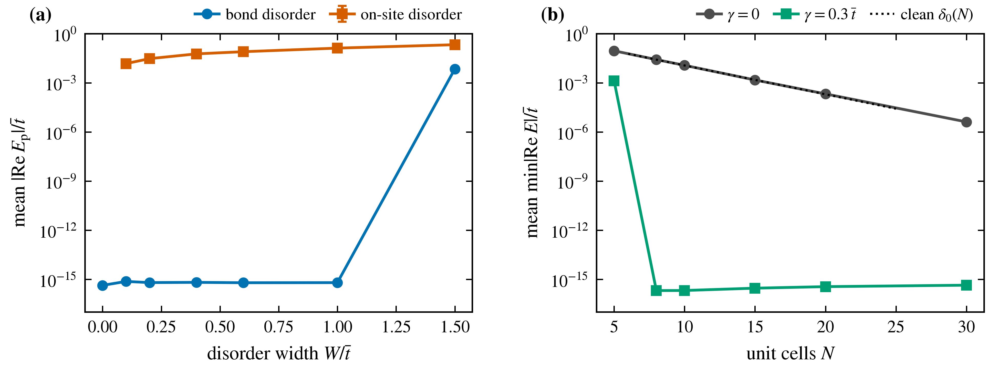

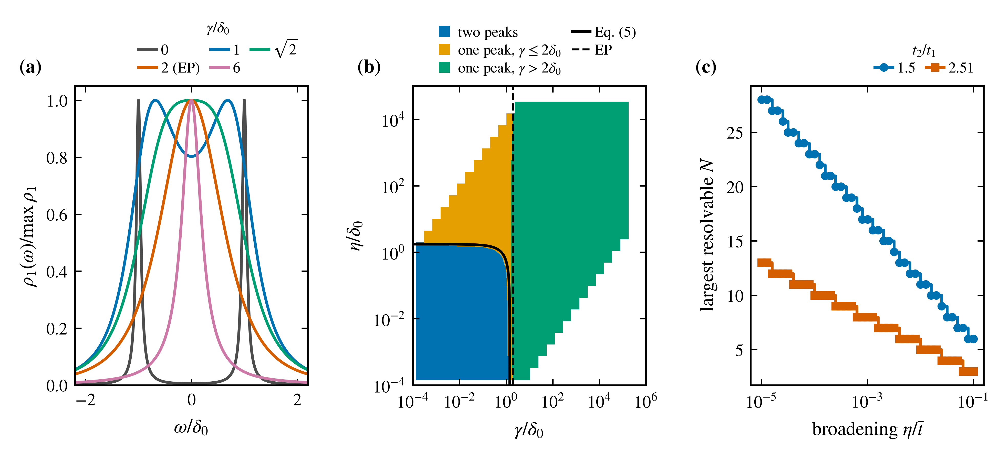

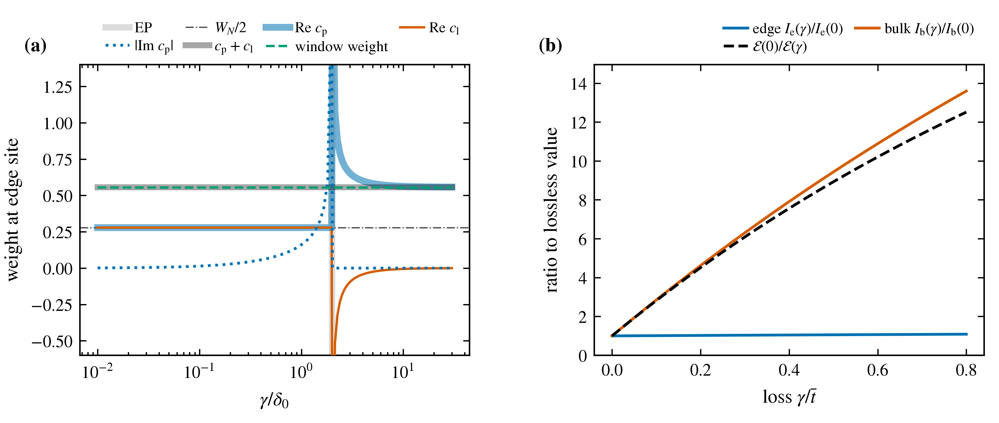

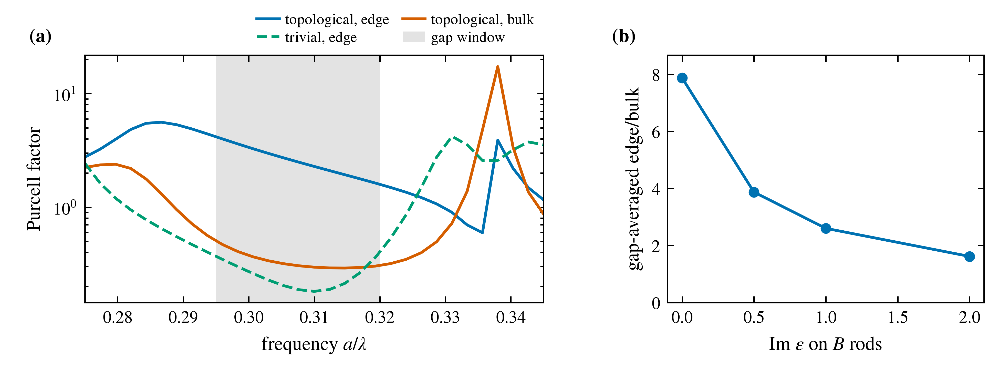

In [35]:
# Figures of the extension and of the conference paper (fig27 to fig30).
d = results["disorder"]
hs = results["hybridisation_vs_size"]
d0s = results["delta0_scaling"]
fig = XF.fig_pinning(np.array(d["W_vals"]), np.array(d["bond_displacement"]),
                     np.array(d["onsite_displacement"]), np.array(d["onsite_displacement_sem"]),
                     np.array(hs["N_vals"]), np.array(hs["splitting"][0]), np.array(hs["splitting"][1]),
                     np.array(d0s["N_vals"]), np.array(d0s["delta0"]))
layout_issues = XF.layout_overlaps(fig)   # legends and labels outside the plot areas
assert not layout_issues, layout_issues
print("fig27_pinning_disorder: layout check passed (no legend or label overlaps a plot area or another label)")
XF.save(fig, FIGDIR, "fig27_pinning_disorder")

# Lineshapes at N = 10, eta = 0.05 delta0, full chain (continued fraction).
x_om = np.linspace(-2.2, 2.2, 2201)
spec_x = [0.0, 1.0, np.sqrt(2), 2.0, 6.0]
spectra = [ob.edge_ldos_continued_fraction(nt.build_ssh(N_A, T1, T2, x * d0_A), x_om * d0_A, 0.05 * d0_A)
           for x in spec_x]
labels = ["0", "1", r"$\sqrt{2}$", "2 (EP)", "6"]
g_red = (A1_GAMMA[None, :, None] / omap["delta0"][:, None, None]) * np.ones_like(omap["cls"], float)
e_red = (A1_ETA[None, None, :] / omap["delta0"][:, None, None]) * np.ones_like(omap["cls"], float)
curve_e = np.concatenate([eta_red, [np.sqrt(3)]])
curve_g = np.concatenate([merge_curve, [0.0]])
keep = curve_g > 1e-5
fig = XF.fig_observability(x_om, spectra, labels, g_red.ravel(), e_red.ravel(), omap["cls"].ravel(),
                           curve_g[keep], curve_e[keep], eta_scan, [nmax_model, nmax_mwratio],
                           ["1.5", f"{r_mw:.2f}"])
layout_issues = XF.layout_overlaps(fig)   # legends and labels outside the plot areas
assert not layout_issues, layout_issues
print("fig28_observability: layout check passed (no legend or label overlaps a plot area or another label)")
XF.save(fig, FIGDIR, "fig28_observability")

fig = XF.fig_weights(x_A2, wd["c_protected"], wd["c_lossy"], wd["c_sum"], wd["window_doublet"],
                     w0_doublet, g_A3, dec["I_edge"], dec["I_bulk"], dec["enhancement"])
layout_issues = XF.layout_overlaps(fig)   # legends and labels outside the plot areas
assert not layout_issues, layout_issues
print("fig29_weights_enhancement: layout check passed (no legend or label overlaps a plot area or another label)")
XF.save(fig, FIGDIR, "fig29_weights_enhancement")

pv = results["photonic_validation"]
ls = results["photonic_loss_series"]
fig = XF.fig_fullwave(np.array(pv["frequencies"]), np.array(pv["topological"]["edge"]),
                      np.array(pv["topological"]["bulk"]), np.array(pv["trivial"]["edge"]),
                      pv["gap_window"], np.array(ls["loss_values"]), np.array(ls["gap_enhancement"]))
layout_issues = XF.layout_overlaps(fig)   # legends and labels outside the plot areas
assert not layout_issues, layout_issues
print("fig30_fullwave: layout check passed (no legend or label overlaps a plot area or another label)")
XF.save(fig, FIGDIR, "fig30_fullwave")
for name in ("fig27_pinning_disorder", "fig28_observability", "fig29_weights_enhancement",
             "fig30_fullwave"):
    display(__import__("IPython").display.Image(f"{FIGDIR}/{name}.png", width=760))

In [36]:
# Consolidated numbers for the conference paper, all taken from this run.
paper = {
    "delta0_N10": results["edge_exceptional_point"]["delta0"],
    "gamma_EP_edge_N10": results["edge_exceptional_point"]["gamma_EP_edge"],
    "EP_separation_N10": results["edge_exceptional_point"]["separation_factor"],
    "W0_analytic": results["ldos"]["W0_analytic"],
    "W0_numeric_N20": results["ldos"]["W0_numeric"],
    "splitting_N20_hermitian": results["hybridisation_vs_disorder"]["splitting"][0][0],
    "splitting_N20_lossy": results["hybridisation_vs_disorder"]["splitting"][1][0],
    "bond_displacement_max": max(results["disorder"]["bond_displacement"][:-1]),
    "bond_displacement_W1p5": results["disorder"]["bond_displacement"][-1],
    "onsite_displacement_W0p1": results["disorder"]["onsite_displacement"][1],
    "onsite_displacement_W1p5": results["disorder"]["onsite_displacement"][-1],
    "enhancement_gamma0": results["enhancement_vs_gamma"][0.0],
    "enhancement_gamma0p3": results["enhancement_vs_gamma"][0.3],
    "fdfd_topological": results["photonic_validation"]["topological"]["gap_enhancement"],
    "fdfd_trivial": results["photonic_validation"]["trivial"]["gap_enhancement"],
    "fdfd_loss_series": results["photonic_loss_series"]["gap_enhancement"],
    "fdfd_loss_values": results["photonic_loss_series"]["loss_values"],
    "fdfd_resolution_spread": results["photonic_resolution_convergence"]["spread"],
    # added in the final audit
    "square_root_law_clean": results["exact_reduction"]["clean"]["square_root_law"],
    "square_root_law_bond_max": max(results["exact_reduction"][k]["bond_square_root_law_max"]
                                    for k in ("W=0.6", "W=1.5")),
    "merging_loss_over_delta0_eta0p05": ob.merging_loss(1.0, 0.05),
    "bulk_min_abs_ReE_A1_grid": min(float(np.sort(np.abs(np.linalg.eigvals(
        nt.build_ssh(int(N), T1, T2, float(A1_GAMMA.max()))).real))[2]) for N in A1_N),
    # added after the blind review
    "bulk_bound_at_gamma_max": float(np.sqrt((T2 - T1) ** 2 - A1_GAMMA.max() ** 2 / 4)),
    "bulk_EP_finite_N10": float(2 * np.sort(np.abs(np.linalg.eigvalsh(
        nt.build_ssh(N_A, T1, T2, 0.0).real)))[2]),
    "asymptotic_delta0_rel_error_N8": float(abs(ob.asymptotic_delta0(8, T1, T2)
                                                / nt.bare_hybridization(8, T1, T2) - 1)),
    "lossy_splitting_min_fig1b": float(np.min(results["hybridisation_vs_size"]["splitting"][1])),
}
ext["paper_numbers"] = paper
with open(os.path.join(RESDIR, "extension_results.json"), "w") as fh:
    json.dump(ext, fh, indent=2, default=float)
for k, v in paper.items():
    print(f"  {k:28s} {v}")
print(f"\nwritten: {RESDIR}/extension_results.json")

  delta0_N10                   0.011578862193852596
  gamma_EP_edge_N10            0.023157724387705192
  EP_separation_N10            34.54570866318509
  W0_analytic                  0.5555555555555555
  W0_numeric_N20               0.5555568029563339
  splitting_N20_hermitian      0.00020048596661724678
  splitting_N20_lossy          3.661778304629904e-16
  bond_displacement_max        7.446085764483783e-16
  bond_displacement_W1p5       0.007096584083580053
  onsite_displacement_W0p1     0.015021439677651273
  onsite_displacement_W1p5     0.2145285508563342
  enhancement_gamma0           68.50705499777968
  enhancement_gamma0p3         11.246698221510508
  fdfd_topological             7.881614582695751
  fdfd_trivial                 0.6921345564336355
  fdfd_loss_series             [7.881614582695751, 3.875222203106356, 2.6031692058509384, 1.6186003277043883]
  fdfd_loss_values             [0.0, 0.5, 1.0, 2.0]
  fdfd_resolution_spread       0.06797902319986743
  square_root_law_clea

### Note on statements in earlier sections

Earlier cells are left unchanged so that the original analysis stays reproducible. Some of their
statements should be read with the results above:

* **The overview in the first cell (item 5), Section 4, "The observable consequence", and the
  Conclusions** say that crossing the edge
  exceptional point doubles the boundary spectral weight, from $W_0/2$ to $W_0$. That holds for the
  residue of the protected pole only (A2). The summed residue of the doublet is $W_N$ on both sides of
  the exceptional point, and the integrated boundary LDOS does not double. At the broadening of
  Section 2 ($\eta = 0.05$, $N = 20$) the two poles are not resolved at all (A1).
* **Section 6 and the Conclusions** report the fall of the edge-to-bulk enhancement with loss as a
  cost of loss ("roughly a factor of six in the magnitude of the boundary response"). For
  $N = 20$, $\eta = 0.05$ the fall comes from the bulk denominator (A3); the gap-integrated edge LDOS
  itself rises slightly, by a factor 1.035 at $\gamma = 0.3$.
* **The edge-exceptional-point cell and the summary table** label the stored quantity
  `max_relative_error_below_EP` as "two-level model vs full spectrum". It compares the edge splitting
  $\min|\mathrm{Re}\,E|$ with the two-level law below the exceptional point, for $N = 10$, relative to
  $\delta_0$. The full spectrum is compared with the square-root law in Section 1
  (`exact_reduction`: $3 \times 10^{-15}$ for the clean chain, at most $3 \times 10^{-14}$ under bond
  disorder).
* **"Pinned" and "exactly on the imaginary axis"** mean $|\mathrm{Re}\,E| < 10^{-8}$, the tolerance
  of `count_pinned_modes`; the stored displacements are of order $10^{-16}$.
* **The overview (item 6), the title of Section 8 ("validation") and the Conclusions** present the
  full-wave calculation as confirming the picture. It shows
  generic edge enhancement and its attenuation by sublattice loss; the eight-cell chain does not
  resolve the doublet, so it does not test the edge exceptional point or the two-peak condition.
* **PT symmetry.** The shifted Hamiltonian is PT symmetric only for the mirror-symmetric clean chain.
  Bond disorder generally breaks the mirror symmetry; the disorder results use only the chiral
  relation of Section 1, which holds realization by realization.
* **Convention.** $\eta$ enters as $\omega + i\eta$, so it is the half-width at half-maximum of a
  Lorentzian probe response. It does not model a probe that changes the self-energy of the chain.
  The curvature of the doublet LDOS at $\omega = 0$ is
  $\rho^{(d)\prime\prime}_1(0) = \frac{2W_N}{\pi}\,\frac{\delta_0^2(2\gamma+3\eta) - (\gamma+\eta)^3}{[\delta_0^2 + \eta(\gamma+\eta)]^3}$,
  whose sign gives the two-peak condition used in A1.

### Additional checks: frequency-grid convergence (A1) and on-site detuning (A5)

The peak count of A1 uses a frequency grid of $2 \times 3000 + 1$ points, spaced logarithmically from
$10^{-10}$ to the window half-width $0.15$ (inside the gap, whose half-width is $|t_2 - t_1| = 0.4$) on
each side of $\omega = 0$ (relative step 0.7%). Peaks are counted with the tie-aware prominence described
at the top of this extension; maxima at the window edges are not counted. The first cell below repeats
the full A1 grid with 1/4 to 2 times as many frequencies.

On-site detuning breaks the symmetry of Section 1, so the exact two-level reduction no longer holds.
The second cell counts peaks in the full edge LDOS of the microwave chain under uniform on-site
detuning of full width $W$, uniform in $[-W/2, W/2]$ (no loss), for the three (N, linewidth) pairs used in
A4. It reports the fraction with a central dip above 1 % and, for comparison, at zero contrast. The
zero-contrast fraction is not a useful measure here: once the detuning exceeds $\delta_0$, the mode at
the far end still leaves a very weak second maximum in the left-edge LDOS (for example 0.2 % of the
main peak), which a zero-contrast count accepts. The 1 % criterion is the one used in the paper.

In [37]:
# A1 convergence: the same grid with 1501, 3001, 6001 (reference) and 12001 frequencies.
t0 = time.time()
conv = {}
for ns in (750, 1500, 3000, 6000):
    m = omap if ns == 3000 else ob.observability_map(A1_N, T1, T2, A1_GAMMA, A1_ETA, GAP_HW,
                                                     A1_PROMINENCE, n_side=ns)
    cf, ct = ob.classes_at_contrast(m, A1_CONTRAST)
    conv[2 * ns + 1] = {"same_binary_as_6001": float(np.mean((m["n_peaks"] >= 2) == (omap["n_peaks"] >= 2))),
                        "agreement_exact_criterion": float(np.mean(m["cls"] == m["cls_analytic"])),
                        "agreement_full_vs_two_level_1pct": float(np.mean(cf == ct))}
print(f"({time.time() - t0:.0f} s)")
for n, v in conv.items():
    print(f"{n:6d} frequencies: same binary count as the 6001 grid {100 * v['same_binary_as_6001']:.2f} %, "
          f"agreement with the two-peak condition {100 * v['agreement_exact_criterion']:.2f} %, "
          f"1 % dip full vs two-level {100 * v['agreement_full_vs_two_level_1pct']:.2f} %")
ext["A1_grid_convergence"] = {str(k): v for k, v in conv.items()}

(96 s)
  1501 frequencies: same binary count as the 6001 grid 100.00 %, agreement with the two-peak condition 100.00 %, 1 % dip full vs two-level 100.00 %
  3001 frequencies: same binary count as the 6001 grid 100.00 %, agreement with the two-peak condition 100.00 %, 1 % dip full vs two-level 100.00 %
  6001 frequencies: same binary count as the 6001 grid 100.00 %, agreement with the two-peak condition 100.00 %, 1 % dip full vs two-level 100.00 %
 12001 frequencies: same binary count as the 6001 grid 100.00 %, agreement with the two-peak condition 100.00 %, 1 % dip full vs two-level 100.00 %


In [38]:
# A5: two-peak fraction under on-site detuning of width W (MHz), microwave couplings, gamma = 0.
A5_W = [0.0, 0.1, 0.3, 1.0, 3.0, 10.0, 20.0]
a5 = []
t0 = time.time()
for n, e in A4_CASES:
    d = nt.bare_hybridization(n, MW_T1, MW_T2)
    rr = [ob.detuning_resolvability(n, MW_T1, MW_T2, w, e, N_REALIZATIONS, SEED,
                                    rel_prominence=A1_CONTRAST) for w in A5_W]
    a5.append({"N": n, "eta_MHz": e, "delta0_MHz": d, "W_MHz": A5_W,
               "criterion": "central dip above 1 % of the peak",
               "fraction_two_peaks": [r["fraction"] for r in rr],
               "fraction_two_peaks_zero_contrast": [r["fraction_zero_contrast"] for r in rr]})
print(f"({time.time() - t0:.0f} s)")
print("fraction of chains with two edge-LDOS peaks (W is the full width); columns W =", A5_W, "MHz")
for r in a5:
    print(f"N = {r['N']}, eta = {r['eta_MHz']:.1f} MHz (delta0 = {r['delta0_MHz']:.3f} MHz), 1 % dip: "
          + "  ".join(f"{f:.3f}" for f in r["fraction_two_peaks"]))
    print(f"{'':>40}zero contrast: " + "  ".join(f"{f:.3f}" for f in r["fraction_two_peaks_zero_contrast"]))
print("binomial standard error at 200 chains: at most 0.035")
print(f"on-site disorder reported by Poli et al.: about 0.15 % of 6.65 GHz = {MW_SCATTER * MW_NU:.1f} MHz")
ext["A5_detuning"] = {"platform": "microwave couplings, Poli et al. 2015", "gamma": 0.0,
                      "n_realizations": N_REALIZATIONS, "seed": SEED, "cases": a5}
with open(os.path.join(RESDIR, "extension_results.json"), "w") as fh:
    json.dump(ext, fh, indent=2, default=float)
print(f"updated: {RESDIR}/extension_results.json")

(14 s)
fraction of chains with two edge-LDOS peaks (W is the full width); columns W = [0.0, 0.1, 0.3, 1.0, 3.0, 10.0, 20.0] MHz
N = 3, eta = 3.0 MHz (delta0 = 2.000 MHz), 1 % dip: 1.000  0.510  0.175  0.060  0.020  0.015  0.015
                                        zero contrast: 1.000  1.000  0.985  0.475  0.170  0.055  0.045
N = 4, eta = 1.0 MHz (delta0 = 0.792 MHz), 1 % dip: 1.000  1.000  0.970  0.425  0.125  0.035  0.020
                                        zero contrast: 1.000  1.000  1.000  0.620  0.235  0.170  0.520
N = 5, eta = 0.3 MHz (delta0 = 0.315 MHz), 1 % dip: 1.000  1.000  1.000  0.750  0.365  0.130  0.135
                                        zero contrast: 1.000  1.000  1.000  1.000  1.000  1.000  1.000
binomial standard error at 200 chains: at most 0.035
on-site disorder reported by Poli et al.: about 0.15 % of 6.65 GHz = 10.0 MHz
updated: results/extension_results.json


### Map from the conference paper to this notebook

| Paper item | Notebook source | Stored result |
|---|---|---|
| Eqs. (1)-(2), exact reduction, EP separation 34.5 (N = 10) | Sections 1 and 4 | `results.json`: `exact_reduction`, `edge_exceptional_point` |
| Fig. 1(a), pinning under bond and on-site disorder | Section 5 | `results.json`: `disorder`; figure `fig27_pinning_disorder` |
| Fig. 1(b), splitting versus N with and without loss | Section 3 | `results.json`: `hybridisation_vs_size`, `delta0_scaling` |
| Eqs. (3)-(5), two-level line shape and two-peak condition | Extension, A1 | `extension_results.json`: `A1` |
| Full-chain peak count, 15 444 points, and its grid convergence | Extension, A1 and checks above | `A1`, `A1_grid_convergence` |
| Peak criterion: zero contrast (Eq. (5)) and a 1 % dip; contrast limits 1.518 and 1.293 | Extension, introduction and A1 | `A1.contrast_threshold`, `A1.eta_over_delta0_limit_by_contrast`, `A1.microwave.max_resolvable_N_by_eta_MHz_at_contrast` |
| Eq. (6) and Fig. 2(c), chain-length bound; microwave estimates | Extension, A1 | `A1.microwave` |
| Fig. 2, observability map and line shapes | Extension, figures cell | figure `fig28_observability` |
| Fig. 3(a), pole residues | Extension, A2 | `A2`; figure `fig29_weights_enhancement` |
| Fig. 3(b), enhancement decomposition | Extension, A3 | `A3` |
| Bond-disorder and detuning resolvability | Extension, A4 and A5 | `A4`, `A5_detuning` |
| Merging loss at $\eta = 0.05\delta_0$ (Fig. 2(a) caption), bulk-pole bound, square-root-law residuals | Extension, paper-numbers cell | `paper_numbers`: `merging_loss_over_delta0_eta0p05`, `bulk_min_abs_ReE_A1_grid`, `square_root_law_clean`, `square_root_law_bond_max` |
| Figure layout (legends and labels outside the plot areas) | Extension, figures cell | `extension_figures.layout_overlaps`; unit test |
| Full-wave rod chain (text only in the paper; figure `fig30_fullwave` here) | Section 8 | `results.json`: `photonic_validation`, `photonic_loss_series`; figure `fig30_fullwave` |